
# Segmentasi Pelanggan UMKM DaMai Coffee & Bakery Menggunakan K-Means Clustering

**Mata Kuliah:** Machine Learning

**Studi Kasus:** Kasus 05 Segmentasi Pelanggan UMKM

**Disusun oleh:**

1. Daniela Ivanka Maydina Siringoringo (2401148)
2. Muhamad Nurhidayat (2401404)

**Program Studi:** Mekatronika dan Kecerdasan Buatan

**Universitas:** Universitas Pendidikan Indonesia

**Tahun:** 2026



## 1. Pendahuluan

DaMai Coffee & Bakery merupakan UMKM fiktif di Bandung yang bergerak di bidang penjualan kopi, roti, kue, dan paket snack. UMKM ini memiliki sekitar 10.000 anggota dengan karakteristik dan perilaku pembelian yang beragam.

Permasalahan utama adalah strategi promosi yang belum mempertimbangkan perbedaan karakteristik pelanggan. Pengiriman promosi yang sama kepada seluruh pelanggan berpotensi menimbulkan pemborosan biaya dan ketidaksesuaian penawaran.

Proyek ini bertujuan mengelompokkan pelanggan menggunakan algoritma K-Means Clustering berdasarkan pola transaksi, nilai belanja, waktu transaksi terakhir, dan penggunaan promo.

Hasil segmentasi digunakan untuk menyusun rekomendasi promosi yang lebih relevan serta mendukung rancangan program loyalitas Green dan Gold Membership.

### Tujuan
1. Menganalisis dan membersihkan data pelanggan.
2. Menentukan jumlah cluster optimal menggunakan metode evaluasi clustering.
3. Mengidentifikasi karakteristik setiap segmen pelanggan.
4. Menghasilkan rekomendasi promosi berdasarkan segmen.
5. Mengembangkan model yang dapat mengelompokkan pelanggan baru.
6. Mengintegrasikan hasil segmentasi ke aplikasi DaMai Coffee & Bakery.


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Library berhasil dimuat.")


Library berhasil dimuat.



## 2. Data Understanding

Dataset yang digunakan berasal dari Kasus 05 — Segmentasi Pelanggan UMKM pada repository pembelajaran Machine Learning.

Dataset berisi ringkasan karakteristik dan aktivitas transaksi pelanggan selama enam bulan hingga Juni 2026.

Tahap awal bertujuan memeriksa struktur data, jumlah observasi, tipe variabel, serta kualitas data sebelum dilakukan praproses dan pemodelan.


In [6]:

DATA_URL = "https://raw.githubusercontent.com/dnielaivnka/damai-customer-segmentation/main/data/raw.csv"

df_raw = pd.read_csv(DATA_URL)

print("Dataset berhasil dimuat.")
print("Jumlah baris:", df_raw.shape[0])
print("Jumlah kolom:", df_raw.shape[1])

display(df_raw.head())


Dataset berhasil dimuat.
Jumlah baris: 10150
Jumlah kolom: 12


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5


In [7]:

display(df_raw.head(10))

print("\nInformasi Dataset:")
df_raw.info()


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5
5,PLG-02982,2025-02-05,30.0,Coblong,toko,ewallet,kopi,3,112200,114,45,4.0
6,PLG-03865,2024-07-13,25.0,Lengkong,gofood,tunai,roti,3,106200,150,67,3.7
7,PLG-08268,2026-02-02,NaN,Buahbatu,grabfood,ewallet,kopi,2,50500,108,37,3.8
8,PLG-07385,2025-09-22,29.0,Coblong,toko,tunai,roti,6,292800,42,64,3.9
9,PLG-05361,2025-05-16,18.0,Cibeunying Kidul,shopeefood,ewallet,paket_snack,10,231500,18,78,NaN



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_pelanggan                   10150 non-null  object 
 1   tanggal_daftar                 10150 non-null  object 
 2   umur                           9942 non-null   float64
 3   kecamatan                      10150 non-null  object 
 4   channel_utama                  10150 non-null  object 
 5   metode_bayar                   10150 non-null  object 
 6   kategori_favorit               10150 non-null  object 
 7   jumlah_transaksi_6bln          10150 non-null  int64  
 8   total_belanja_rp               10150 non-null  object 
 9   hari_sejak_transaksi_terakhir  10150 non-null  int64  
 10  persen_pakai_promo             10150 non-null  int64  
 11  rating_rata                    9338 non-null   float64
dtypes: float64(2), int64(3), o


## 3. Data Quality Assessment

Tahap ini bertujuan mengidentifikasi permasalahan kualitas data sebelum pemodelan, meliputi missing values, duplikasi, ketidaksesuaian tipe data, inkonsistensi kategori, dan nilai yang tidak wajar.

Hasil pemeriksaan digunakan sebagai dasar penentuan metode pembersihan data agar informasi pelanggan tetap terjaga.


In [8]:

ringkasan_kualitas = pd.DataFrame({
    "Tipe Data": df_raw.dtypes.astype(str),
    "Jumlah Kosong": df_raw.isna().sum(),
    "Persentase Kosong (%)": (df_raw.isna().mean() * 100).round(2),
    "Jumlah Nilai Unik": df_raw.nunique()
})

display(ringkasan_kualitas)

print("Total baris:", len(df_raw))
print("Pelanggan unik:", df_raw["id_pelanggan"].nunique())
print("Duplikat identik:", df_raw.duplicated().sum())
print("ID pelanggan berulang:", df_raw.duplicated(subset=["id_pelanggan"]).sum())


,Tipe Data,Jumlah Kosong,Persentase Kosong (%),Jumlah Nilai Unik
id_pelanggan,object,0,0.00,10000
tanggal_daftar,object,0,0.00,870
umur,float64,208,2.05,47
kecamatan,object,0,0.00,15
channel_utama,object,0,0.00,4
metode_bayar,object,0,0.00,4
kategori_favorit,object,0,0.00,4
jumlah_transaksi_6bln,int64,0,0.00,53
total_belanja_rp,object,0,0.00,7345
hari_sejak_transaksi_terakhir,int64,0,0.00,209


Total baris: 10150
Pelanggan unik: 10000
Duplikat identik: 90
ID pelanggan berulang: 150


In [9]:

print("Nilai umur yang tidak wajar:")
display(df_raw["umur"].value_counts().sort_index().loc[
    lambda x: (x.index < 2) | (x.index > 90)
])

print("\nContoh format total belanja:")
display(df_raw["total_belanja_rp"].sample(
    10, random_state=42
))

print("\nVariasi penulisan kecamatan:")
display(df_raw["kecamatan"].value_counts())

print("\nRingkasan statistik numerik:")
display(df_raw.describe().round(2))


Nilai umur yang tidak wajar:


,count
umur,
0.0,27
1.0,20
99.0,25
120.0,28



Contoh format total belanja:


,total_belanja_rp
621,1405300
4385,299000
6794,345300
4562,1085200
9264,1837200
3132,26500
8710,455800
5737,106300
7782,1410000
6503,695500



Variasi penulisan kecamatan:


,count
kecamatan,
Buahbatu,1046
Cidadap,1029
Sumur Bandung,1002
Arcamanik,1000
Sukajadi,989
Bandung Wetan,984
Lengkong,976
Antapani,976
Coblong,951



Ringkasan statistik numerik:


,umur,jumlah_transaksi_6bln,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
count,9942.00,10150.00,10150.00,10150.00,9338.00
mean,29.18,12.52,41.86,38.49,4.15
std,9.99,11.63,49.45,28.02,0.52
min,0.00,1.00,0.00,0.00,2.00
25%,23.00,3.00,6.00,16.00,3.80
50%,28.00,8.00,16.00,28.00,4.20
75%,34.00,20.00,75.00,65.75,4.50
max,120.00,56.00,225.00,100.00,5.00


In [10]:

data_duplikat = df_raw[
    df_raw.duplicated(subset=["id_pelanggan"], keep=False)
].sort_values("id_pelanggan")

print("Jumlah baris dengan ID berulang:", len(data_duplikat))
print("Jumlah ID yang berulang:", data_duplikat["id_pelanggan"].nunique())

display(data_duplikat.head(12))


Jumlah baris dengan ID berulang: 300
Jumlah ID yang berulang: 150


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
3145,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
5398,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
95,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
6998,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
1255,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.2
8828,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.2
3655,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
9620,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
1559,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6
9524,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6



### Temuan Awal Kualitas Data

Pemeriksaan awal menunjukkan bahwa dataset memiliki 10.150 baris dengan 10.000 ID pelanggan unik. Ditemukan 90 baris duplikat identik dan 150 kemunculan ID berulang di luar kemunculan pertamanya.

Selain itu, terdapat 208 nilai kosong pada kolom umur dan 812 nilai kosong pada kolom rating. Kolom total belanja masih menggunakan tipe data teks karena sebagian nilai mengandung format mata uang.

Ditemukan pula nilai umur yang tidak wajar dan inkonsistensi penulisan kecamatan.

Temuan tersebut menunjukkan perlunya tahap data cleaning sebelum analisis perilaku pelanggan dan penerapan algoritma K-Means. Penanganan data akan mempertimbangkan jenis kesalahan agar tidak menghilangkan informasi yang masih valid.



## 4. Data Cleaning

Tahap pembersihan data dilakukan untuk meningkatkan konsistensi dan kualitas dataset sebelum proses analisis dan clustering.

Proses meliputi penanganan duplikasi pelanggan, konversi nominal belanja, standardisasi kategori, serta validasi nilai numerik dan tanggal.

Nilai yang tidak valid akan ditangani tanpa menghapus seluruh informasi pelanggan. Hasil pembersihan digunakan sebagai dasar untuk Exploratory Data Analysis dan pemodelan K-Means.


In [11]:

df_clean = df_raw.copy()

print("Jumlah data sebelum cleaning:", len(df_clean))
print("Jumlah pelanggan unik:", df_clean["id_pelanggan"].nunique())


Jumlah data sebelum cleaning: 10150
Jumlah pelanggan unik: 10000


In [12]:

jumlah_awal = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

kolom_pemeriksaan = [
    kolom for kolom in df_clean.columns
    if kolom not in ["id_pelanggan", "hari_sejak_transaksi_terakhir"]
]

pemeriksaan_konflik = (
    df_clean.groupby("id_pelanggan")[kolom_pemeriksaan]
    .nunique(dropna=False)
)

jumlah_konflik = pemeriksaan_konflik.gt(1).any(axis=1).sum()

if jumlah_konflik > 0:
    raise ValueError("Terdapat konflik data pelanggan yang perlu diperiksa.")

df_clean = (
    df_clean
    .sort_values(
        ["id_pelanggan", "hari_sejak_transaksi_terakhir"],
        ascending=[True, True]
    )
    .drop_duplicates(subset="id_pelanggan", keep="first")
    .reset_index(drop=True)
)

print("Data awal:", jumlah_awal)
print("Duplikat identik:", 90)
print("ID tambahan yang berulang:", 60)
print("Data setelah cleaning:", len(df_clean))
print("Pelanggan unik:", df_clean["id_pelanggan"].nunique())


Data awal: 10150
Duplikat identik: 90
ID tambahan yang berulang: 60
Data setelah cleaning: 10000
Pelanggan unik: 10000


In [13]:

df_clean["total_belanja_rp"] = pd.to_numeric(
    df_clean["total_belanja_rp"]
    .astype("string")
    .str.replace(r"(?i)^\s*rp\s*", "", regex=True)
    .str.replace(".", "", regex=False)
    .str.strip(),
    errors="coerce"
)

print("Tipe data:", df_clean["total_belanja_rp"].dtype)
print("Nilai gagal dikonversi:", df_clean["total_belanja_rp"].isna().sum())

display(
    df_clean[["id_pelanggan", "total_belanja_rp"]].head(10)
)


Tipe data: Int64
Nilai gagal dikonversi: 0


,id_pelanggan,total_belanja_rp
0,PLG-00001,136500
1,PLG-00002,957800
2,PLG-00003,827400
3,PLG-00004,85500
4,PLG-00005,480500
5,PLG-00006,148300
6,PLG-00007,75000
7,PLG-00008,1016900
8,PLG-00009,169100
9,PLG-00010,33100


In [14]:

df_clean["kecamatan"] = (
    df_clean["kecamatan"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "bdg wetan": "bandung wetan",
        "buah batu": "buahbatu"
    })
    .str.title()
)

kolom_kategori = [
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

for kolom in kolom_kategori:
    df_clean[kolom] = (
        df_clean[kolom]
        .astype("string")
        .str.strip()
        .str.lower()
    )

print("Jumlah kecamatan unik:", df_clean["kecamatan"].nunique())

display(df_clean["kecamatan"].value_counts())


Jumlah kecamatan unik: 10


,count
kecamatan,
Buahbatu,1077
Sukajadi,1037
Bandung Wetan,1024
Cidadap,1018
Sumur Bandung,989
Arcamanik,984
Coblong,979
Antapani,968
Cibeunying Kidul,964


In [15]:

TANGGAL_REFERENSI = pd.Timestamp("2026-06-30")

df_clean["tanggal_daftar"] = pd.to_datetime(
    df_clean["tanggal_daftar"],
    errors="coerce"
)

umur_invalid = (
    df_clean["umur"].notna()
    & ~df_clean["umur"].between(15, 110)
)

df_clean.loc[umur_invalid, "umur"] = np.nan

usia_keanggotaan = (
    TANGGAL_REFERENSI - df_clean["tanggal_daftar"]
).dt.days

recency_invalid = (
    (df_clean["hari_sejak_transaksi_terakhir"] < 0)
    | (df_clean["hari_sejak_transaksi_terakhir"] > usia_keanggotaan)
)

df_clean.loc[
    recency_invalid,
    "hari_sejak_transaksi_terakhir"
] = np.nan

df_clean.loc[
    df_clean["jumlah_transaksi_6bln"] <= 0,
    "jumlah_transaksi_6bln"
] = np.nan

df_clean.loc[
    df_clean["total_belanja_rp"] < 0,
    "total_belanja_rp"
] = np.nan

df_clean.loc[
    ~df_clean["persen_pakai_promo"].between(0, 100),
    "persen_pakai_promo"
] = np.nan

df_clean.loc[
    ~df_clean["rating_rata"].between(1, 5),
    "rating_rata"
] = np.nan

print("Umur tidak valid:", umur_invalid.sum())
print("Recency tidak konsisten:", recency_invalid.sum())
print("Jumlah pelanggan:", len(df_clean))


Umur tidak valid: 75
Recency tidak konsisten: 283
Jumlah pelanggan: 10000


In [16]:

ringkasan_akhir = pd.DataFrame({
    "Tipe Data": df_clean.dtypes.astype(str),
    "Missing Values": df_clean.isna().sum(),
    "Missing (%)": (
        df_clean.isna().mean() * 100
    ).round(2),
    "Nilai Unik": df_clean.nunique()
})

display(ringkasan_akhir)

print("Jumlah baris akhir:", len(df_clean))
print("Pelanggan unik:", df_clean["id_pelanggan"].nunique())
print("Duplikat ID:", df_clean.duplicated("id_pelanggan").sum())

assert len(df_clean) == 10000
assert df_clean["id_pelanggan"].is_unique
assert pd.api.types.is_numeric_dtype(df_clean["total_belanja_rp"])

print("Validasi data cleaning berhasil.")

display(df_clean.head())


,Tipe Data,Missing Values,Missing (%),Nilai Unik
id_pelanggan,object,0,0.00,10000
tanggal_daftar,datetime64[ns],0,0.00,870
umur,float64,275,2.75,44
kecamatan,string,0,0.00,10
channel_utama,string,0,0.00,4
metode_bayar,string,0,0.00,4
kategori_favorit,string,0,0.00,4
jumlah_transaksi_6bln,float64,0,0.00,53
total_belanja_rp,Int64,0,0.00,7101
hari_sejak_transaksi_terakhir,float64,283,2.83,206


Jumlah baris akhir: 10000
Pelanggan unik: 10000
Duplikat ID: 0
Validasi data cleaning berhasil.


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-00001,2026-03-23,18.0,Arcamanik,gofood,qris,kopi,2.0,136500,NaN,57.0,4.0
1,PLG-00002,2024-08-17,33.0,Buahbatu,grabfood,qris,kue_ulang_tahun,5.0,957800,43.0,20.0,4.7
2,PLG-00003,2024-06-27,30.0,Sumur Bandung,toko,ewallet,kue_ulang_tahun,22.0,827400,2.0,3.0,5.0
3,PLG-00004,2026-04-20,27.0,Bandung Wetan,toko,ewallet,kopi,2.0,85500,NaN,14.0,2.5
4,PLG-00005,2024-12-26,17.0,Coblong,gofood,tunai,kue_ulang_tahun,12.0,480500,9.0,81.0,4.4


In [17]:

df_clean.to_csv(
    "damai_customers_cleaned.csv",
    index=False
)

print("Dataset bersih berhasil disimpan.")
print("Nama file: damai_customers_cleaned.csv")
print("Total pelanggan:", len(df_clean))


Dataset bersih berhasil disimpan.
Nama file: damai_customers_cleaned.csv
Total pelanggan: 10000



## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis dilakukan untuk memahami karakteristik dan perilaku pelanggan DaMai Coffee & Bakery sebelum proses clustering.

Analisis berfokus pada empat indikator utama, yaitu Recency (waktu sejak transaksi terakhir), Frequency (frekuensi transaksi), Monetary (total belanja), dan persentase penggunaan promo.

Analisis juga mencakup kategori produk favorit, saluran pembelian, dan persebaran pelanggan berdasarkan kecamatan.

Hasil EDA digunakan sebagai dasar pemilihan fitur, strategi praproses, dan interpretasi segmentasi pelanggan.


In [18]:

from matplotlib.ticker import FuncFormatter

WARNA = {
    "espresso": "#4B3428",
    "coffee": "#806044",
    "sage": "#8DA796",
    "gold": "#C9A45C",
    "terracotta": "#C98D71",
    "ivory": "#F8F6F1"
}

sns.set_theme(
    style="whitegrid",
    font_scale=1.0,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white"
    }
)

print("Tema visualisasi DaMai berhasil diterapkan.")


Tema visualisasi DaMai berhasil diterapkan.


In [19]:

fitur_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

statistik = (
    df_clean[fitur_numerik]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .T
    .round(2)
)

display(statistik)

print(f"Total pelanggan: {len(df_clean):,}")
print(f"Median transaksi: {df_clean['jumlah_transaksi_6bln'].median():.0f} kali")
print(f"Median belanja: Rp{df_clean['total_belanja_rp'].median():,.0f}")
print(f"Median recency: {df_clean['hari_sejak_transaksi_terakhir'].median():.0f} hari")
print(f"Median penggunaan promo: {df_clean['persen_pakai_promo'].median():.1f}%")


,count,mean,std,min,25%,50%,75%,90%,max
umur,9725.0,29.079383,8.564589,16.0,23.0,28.0,34.0,39.0,99.0
jumlah_transaksi_6bln,10000.0,12.535,11.643029,1.0,3.0,8.0,20.0,31.0,56.0
total_belanja_rp,10000.0,693710.74,648750.915942,11900.0,152200.0,425050.0,1145325.0,1663930.0,3424200.0
hari_sejak_transaksi_terakhir,9717.0,39.493259,47.863735,0.0,6.0,15.0,64.0,122.0,225.0
persen_pakai_promo,10000.0,38.4808,28.020581,0.0,16.0,28.0,65.0,83.0,100.0
rating_rata,9200.0,4.153728,0.524695,2.0,3.8,4.2,4.5,4.8,5.0


Total pelanggan: 10,000
Median transaksi: 8 kali
Median belanja: Rp425,050
Median recency: 15 hari
Median penggunaan promo: 28.0%


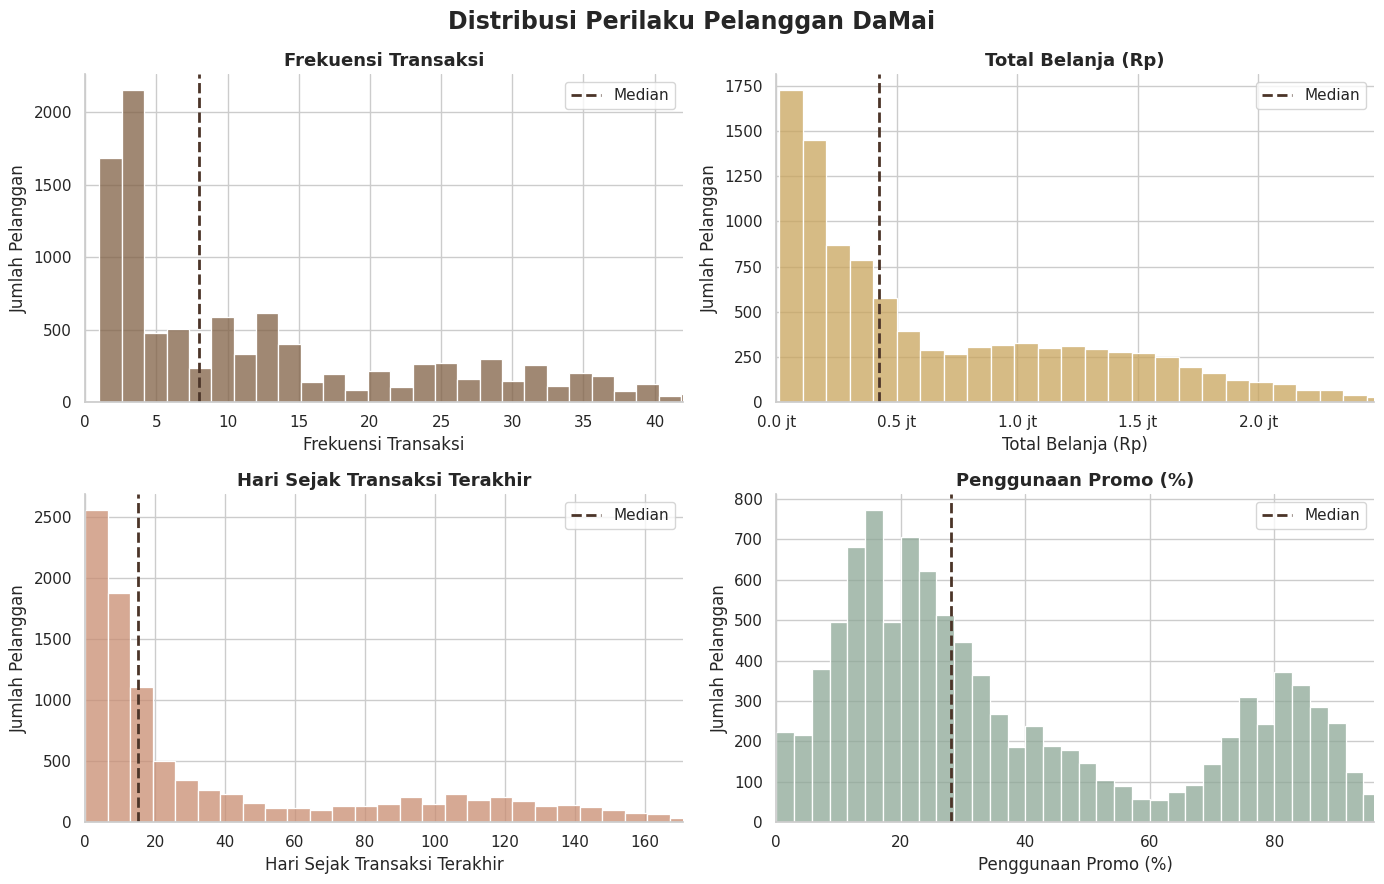

In [20]:

fitur_eda = [
    ("jumlah_transaksi_6bln", "Frekuensi Transaksi", WARNA["coffee"]),
    ("total_belanja_rp", "Total Belanja (Rp)", WARNA["gold"]),
    ("hari_sejak_transaksi_terakhir", "Hari Sejak Transaksi Terakhir", WARNA["terracotta"]),
    ("persen_pakai_promo", "Penggunaan Promo (%)", WARNA["sage"])
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (kolom, judul, warna) in zip(axes.flat, fitur_eda):
    nilai = df_clean[kolom].dropna()

    sns.histplot(
        nilai,
        bins=35,
        color=warna,
        edgecolor="white",
        ax=ax
    )

    ax.axvline(
        nilai.median(),
        color=WARNA["espresso"],
        linestyle="--",
        linewidth=2,
        label="Median"
    )

    ax.set_xlim(left=0, right=max(nilai.quantile(0.99), 1))
    ax.set_title(judul, fontsize=13, fontweight="bold")
    ax.set_xlabel(judul)
    ax.set_ylabel("Jumlah Pelanggan")
    ax.legend()

axes[0, 1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt")
)

plt.suptitle(
    "Distribusi Perilaku Pelanggan DaMai",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


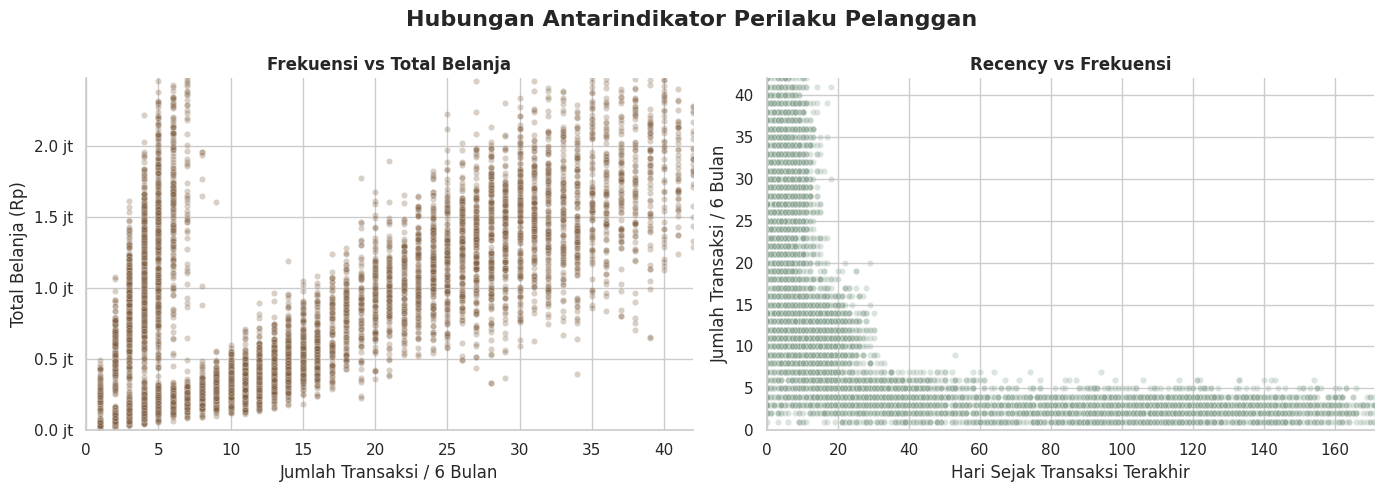

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_clean,
    x="jumlah_transaksi_6bln",
    y="total_belanja_rp",
    color=WARNA["coffee"],
    alpha=0.3,
    s=20,
    ax=axes[0]
)

axes[0].set_xlim(
    0, df_clean["jumlah_transaksi_6bln"].quantile(0.99)
)
axes[0].set_ylim(
    0, df_clean["total_belanja_rp"].quantile(0.99)
)
axes[0].set_title("Frekuensi vs Total Belanja", fontweight="bold")
axes[0].set_xlabel("Jumlah Transaksi / 6 Bulan")
axes[0].set_ylabel("Total Belanja (Rp)")
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt")
)

sns.scatterplot(
    data=df_clean,
    x="hari_sejak_transaksi_terakhir",
    y="jumlah_transaksi_6bln",
    color=WARNA["sage"],
    alpha=0.3,
    s=20,
    ax=axes[1]
)

axes[1].set_xlim(
    0, df_clean["hari_sejak_transaksi_terakhir"].quantile(0.99)
)
axes[1].set_ylim(
    0, df_clean["jumlah_transaksi_6bln"].quantile(0.99)
)
axes[1].set_title("Recency vs Frekuensi", fontweight="bold")
axes[1].set_xlabel("Hari Sejak Transaksi Terakhir")
axes[1].set_ylabel("Jumlah Transaksi / 6 Bulan")

plt.suptitle(
    "Hubungan Antarindikator Perilaku Pelanggan",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


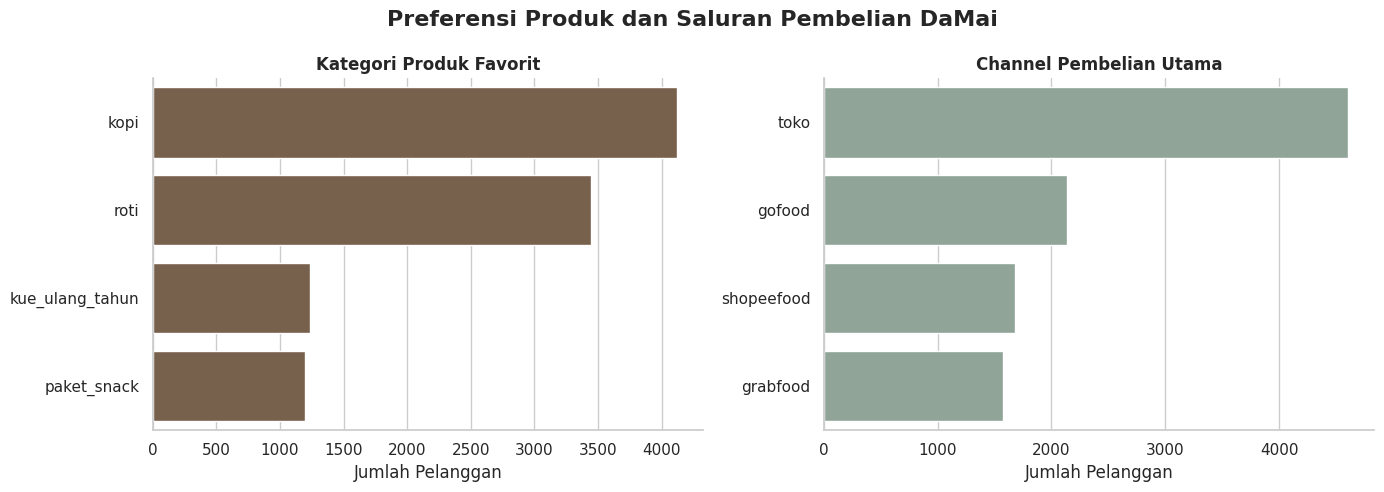

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

kategori = df_clean["kategori_favorit"].value_counts()
channel = df_clean["channel_utama"].value_counts()

sns.barplot(
    x=kategori.values,
    y=kategori.index,
    color=WARNA["coffee"],
    ax=axes[0]
)

sns.barplot(
    x=channel.values,
    y=channel.index,
    color=WARNA["sage"],
    ax=axes[1]
)

axes[0].set_title("Kategori Produk Favorit", fontweight="bold")
axes[1].set_title("Channel Pembelian Utama", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Jumlah Pelanggan")
    ax.set_ylabel("")

plt.suptitle(
    "Preferensi Produk dan Saluran Pembelian DaMai",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


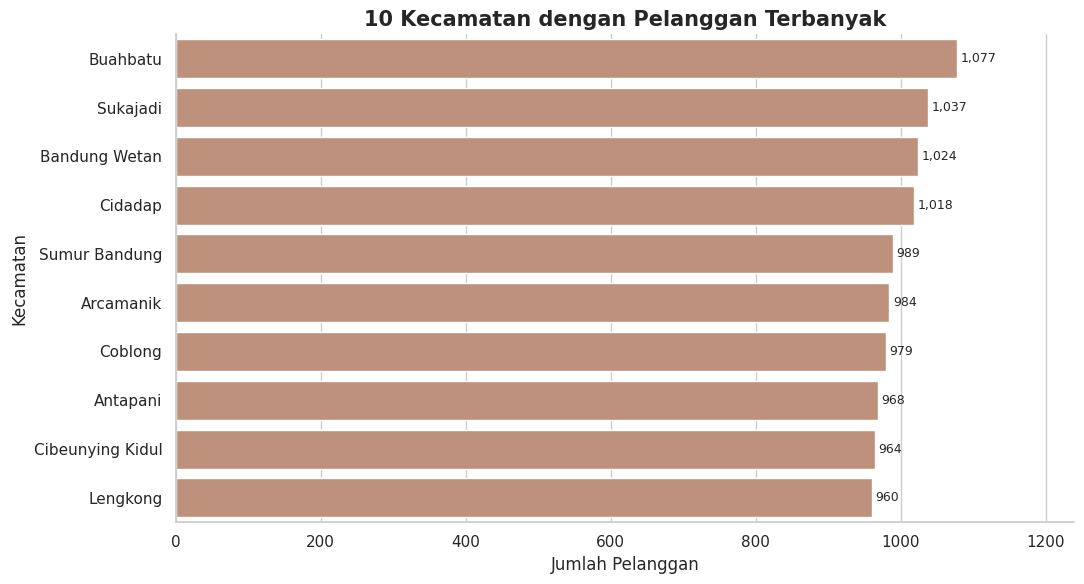

In [23]:

kecamatan = df_clean["kecamatan"].value_counts().head(10)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=kecamatan.values,
    y=kecamatan.index,
    color=WARNA["terracotta"]
)

plt.title(
    "10 Kecamatan dengan Pelanggan Terbanyak",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Jumlah Pelanggan")
plt.ylabel("Kecamatan")

for i, nilai in enumerate(kecamatan.values):
    ax.text(nilai + 5, i, f"{nilai:,}", va="center", fontsize=9)

plt.xlim(0, kecamatan.max() * 1.15)
plt.tight_layout()
plt.show()


,status_aktivitas,jumlah_pelanggan,median_transaksi,median_belanja,median_promo,persentase_pelanggan
0,Aktif (0–14 hari),4836,21.0,944200.0,25.0,48.36
1,Mulai Jarang (15–60 hari),2391,5.0,529000.0,21.0,23.91
2,Lama Tidak Bertransaksi (>60 hari),2490,3.0,99250.0,34.0,24.90


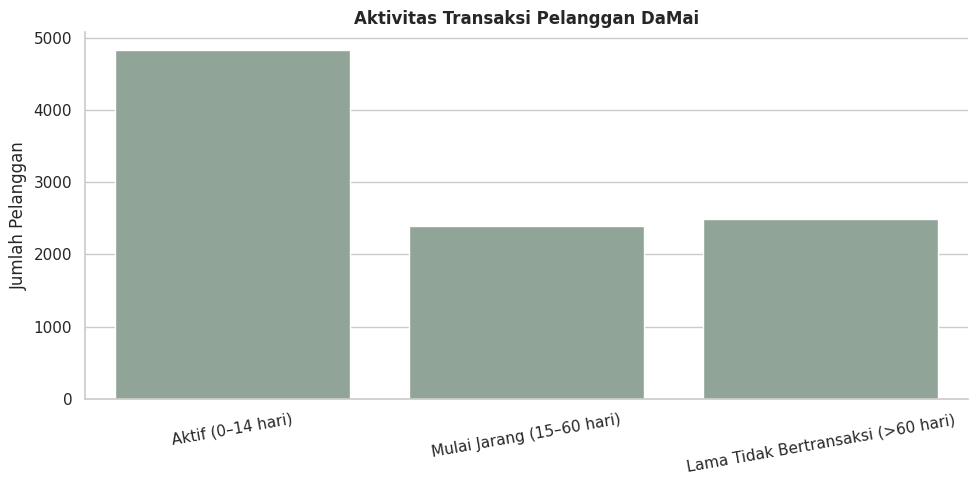

In [24]:

df_aktivitas = df_clean.copy()

df_aktivitas["status_aktivitas"] = pd.cut(
    df_aktivitas["hari_sejak_transaksi_terakhir"],
    bins=[-1, 14, 60, np.inf],
    labels=[
        "Aktif (0–14 hari)",
        "Mulai Jarang (15–60 hari)",
        "Lama Tidak Bertransaksi (>60 hari)"
    ]
)

ringkasan_aktivitas = (
    df_aktivitas.groupby("status_aktivitas", observed=True)
    .agg(
        jumlah_pelanggan=("id_pelanggan", "count"),
        median_transaksi=("jumlah_transaksi_6bln", "median"),
        median_belanja=("total_belanja_rp", "median"),
        median_promo=("persen_pakai_promo", "median")
    )
    .reset_index()
)

ringkasan_aktivitas["persentase_pelanggan"] = (
    ringkasan_aktivitas["jumlah_pelanggan"]
    / len(df_clean) * 100
).round(2)

display(ringkasan_aktivitas)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ringkasan_aktivitas,
    x="status_aktivitas",
    y="jumlah_pelanggan",
    color=WARNA["sage"]
)

plt.title("Aktivitas Transaksi Pelanggan DaMai", fontweight="bold")
plt.xlabel("")
plt.ylabel("Jumlah Pelanggan")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()



### 5.1 Interpretasi Hasil EDA

Hasil analisis menunjukkan adanya variasi perilaku pembelian pelanggan DaMai Coffee & Bakery.

Sebanyak 48,36% pelanggan melakukan transaksi dalam 14 hari terakhir, sedangkan 23,91% berada pada rentang 15–60 hari dan 24,90% tidak bertransaksi selama lebih dari 60 hari. Sebanyak 2,83% pelanggan memiliki data recency yang belum valid.

Pelanggan aktif memiliki median 21 transaksi dan total belanja Rp944.200 selama enam bulan. Sebaliknya, pelanggan yang lama tidak bertransaksi memiliki median 3 transaksi dan total belanja Rp99.250.

Perbedaan tersebut menunjukkan bahwa frekuensi pembelian, nilai belanja, dan waktu transaksi terakhir berpotensi menjadi variabel penting untuk segmentasi pelanggan.

Namun, kategori aktivitas pada tahap EDA hanya digunakan sebagai analisis deskriptif. Penentuan segmen akhir dilakukan menggunakan algoritma K-Means berdasarkan kemiripan karakteristik pelanggan.



## 6. Feature Engineering dan Preprocessing

Tahap ini mempersiapkan variabel untuk proses clustering menggunakan empat indikator perilaku pelanggan:

1. **Recency (R):** Jumlah hari sejak transaksi terakhir.
2. **Frequency (F):** Jumlah transaksi selama enam bulan.
3. **Monetary (M):** Total belanja selama enam bulan.
4. **Promo Usage (P):** Persentase transaksi yang menggunakan promo.

Keempat fitur dipilih karena menggambarkan aktivitas, nilai ekonomi, serta kecenderungan pelanggan dalam memanfaatkan promosi.

Nilai kosong pada fitur model ditangani menggunakan imputasi median. Selanjutnya, standardisasi dilakukan agar perbedaan satuan dan rentang angka tidak menyebabkan fitur tertentu mendominasi perhitungan jarak K-Means.

Pada tahap baseline, standardisasi diterapkan langsung. Eksperimen berikutnya akan menguji transformasi logaritmik untuk memperbaiki distribusi fitur yang menceng.


In [25]:

import sys
import subprocess
from pathlib import Path

repo_dir = Path("/content/damai-customer-segmentation")

if not repo_dir.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/dnielaivnka/damai-customer-segmentation.git",
            str(repo_dir)
        ],
        check=True
    )

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

from src.features import prepare_features, FEATURE_COLUMNS

fitur_clustering = FEATURE_COLUMNS
X = prepare_features(df_clean)

print("Sumber fitur: src/features.py")
print("Jumlah pelanggan:", len(X))
print("Jumlah fitur:", X.shape[1])

display(X.head())
display(X.isna().sum().to_frame("Jumlah Kosong"))


Sumber fitur: src/features.py
Jumlah pelanggan: 10000
Jumlah fitur: 4


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp,persen_pakai_promo
0,NaN,2.0,136500,57.0
1,43.0,5.0,957800,20.0
2,2.0,22.0,827400,3.0
3,NaN,2.0,85500,14.0
4,9.0,12.0,480500,81.0


,Jumlah Kosong
hari_sejak_transaksi_terakhir,283
jumlah_transaksi_6bln,0
total_belanja_rp,0
persen_pakai_promo,0


In [26]:

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessing_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_baseline = preprocessing_baseline.fit_transform(X)

print("Ukuran data:", X_baseline.shape)
print("Jumlah NaN tersisa:", np.isnan(X_baseline).sum())

display(
    pd.DataFrame(
        X_baseline,
        columns=fitur_clustering
    ).head()
)


Ukuran data: (10000, 4)
Jumlah NaN tersisa: 0


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp,persen_pakai_promo
0,-0.502603,-0.904878,-0.858941,0.660947
1,0.088692,-0.647201,0.407094,-0.659577
2,-0.777133,0.812973,0.206082,-1.266304
3,-0.502603,-0.904878,-0.937557,-0.873716
4,-0.629309,-0.045953,-0.328665,1.517503



## 7. Pemodelan K-Means Baseline

K-Means merupakan algoritma unsupervised learning yang mengelompokkan pelanggan berdasarkan kedekatan karakteristiknya.

Jumlah cluster dinyatakan dengan parameter k. Karena jumlah kelompok ideal belum diketahui, dilakukan eksperimen beberapa nilai k.

Evaluasi menggunakan:

- **Silhouette Score:** Mengukur kualitas pemisahan antarcluster. Semakin tinggi semakin baik.
- **Inertia:** Mengukur jumlah kuadrat jarak data terhadap pusat cluster. Digunakan dalam Elbow Method.
- **Davies-Bouldin Index:** Mengukur kemiripan antarkelompok. Semakin rendah semakin baik.

Eksperimen baseline menggunakan empat fitur yang telah distandardisasi tanpa transformasi logaritmik.


In [27]:

from sklearn.metrics import silhouette_score, davies_bouldin_score

hasil_baseline = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_baseline)

    silhouette = silhouette_score(
        X_baseline,
        labels,
        sample_size=1800,
        random_state=RANDOM_STATE
    )

    dbi = davies_bouldin_score(
        X_baseline, labels
    )

    hasil_baseline.append({
        "k": k,
        "Silhouette Score": silhouette,
        "Inertia": model.inertia_,
        "Davies-Bouldin Index": dbi
    })

df_baseline = pd.DataFrame(hasil_baseline)

display(df_baseline.round(4))


,k,Silhouette Score,Inertia,Davies-Bouldin Index
0,2,0.4134,22332.4170,1.0032
1,3,0.5036,12770.8886,0.7050
2,4,0.5394,7739.6092,0.7373
3,5,0.5093,6392.2649,0.7903
4,6,0.4916,5093.7690,0.8050
5,7,0.4484,4432.7323,0.8886
6,8,0.4342,3995.6979,0.9146


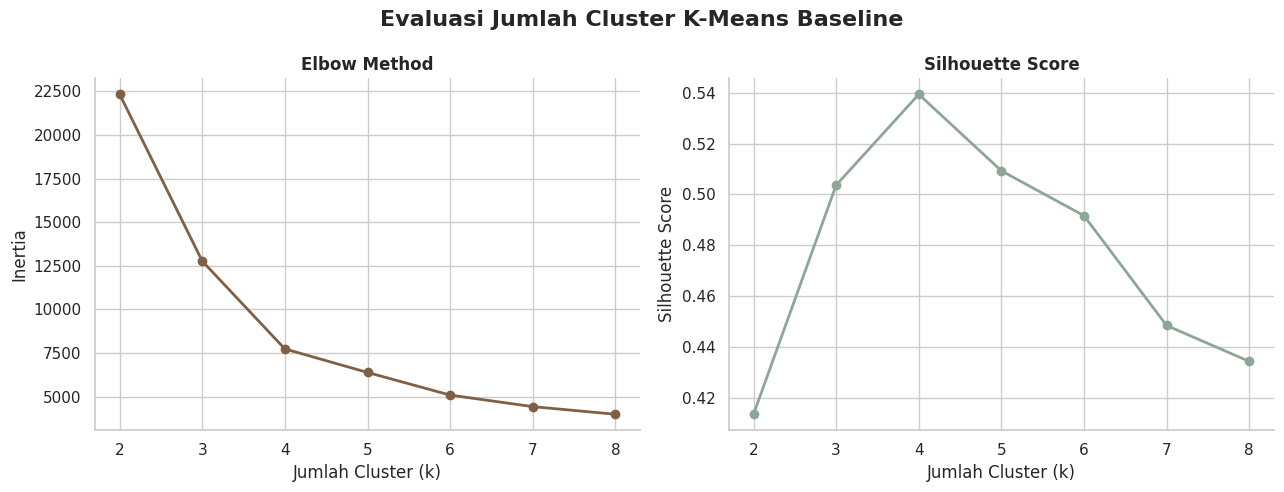

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    df_baseline["k"],
    df_baseline["Inertia"],
    marker="o",
    linewidth=2,
    color=WARNA["coffee"]
)

axes[0].set_title("Elbow Method", fontweight="bold")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(2, 9))

axes[1].plot(
    df_baseline["k"],
    df_baseline["Silhouette Score"],
    marker="o",
    linewidth=2,
    color=WARNA["sage"]
)

axes[1].set_title("Silhouette Score", fontweight="bold")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(range(2, 9))

plt.suptitle(
    "Evaluasi Jumlah Cluster K-Means Baseline",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [29]:

hasil_terbaik = df_baseline.loc[
    df_baseline["Silhouette Score"].idxmax()
]

print("HASIL K-MEANS BASELINE")
print(f"Jumlah cluster terbaik sementara: {int(hasil_terbaik['k'])}")
print(f"Silhouette Score: {hasil_terbaik['Silhouette Score']:.4f}")
print(f"Davies-Bouldin Index: {hasil_terbaik['Davies-Bouldin Index']:.4f}")
print(f"Inertia: {hasil_terbaik['Inertia']:.2f}")


HASIL K-MEANS BASELINE
Jumlah cluster terbaik sementara: 4
Silhouette Score: 0.5394
Davies-Bouldin Index: 0.7373
Inertia: 7739.61



### 7.1 Interpretasi Hasil Baseline

Pengujian K-Means dilakukan untuk jumlah cluster k=2 hingga k=8 menggunakan empat fitur perilaku pelanggan yang telah distandardisasi.

Hasil evaluasi menunjukkan bahwa k=4 memperoleh Silhouette Score tertinggi sebesar 0,5394, dengan inertia 7739,61 dan Davies-Bouldin Index 0,7373.

Nilai tersebut menunjukkan bahwa empat cluster merupakan kandidat yang baik berdasarkan pemisahan antarkelompok. Meskipun demikian, Davies-Bouldin Index terendah diperoleh pada k=3, sehingga pemilihan model perlu mempertimbangkan beberapa metrik serta interpretasi bisnis.

Tahap berikutnya dilakukan untuk mengevaluasi apakah transformasi logaritmik dapat meningkatkan kualitas clustering dibandingkan baseline.



## 8. Optimasi Model K-Means

Optimasi dilakukan dengan menerapkan transformasi logaritmik pada fitur Recency, Frequency, dan Monetary.

Transformasi ini digunakan untuk mengurangi pengaruh distribusi yang menceng dan perbedaan nilai ekstrem tanpa langsung menghapus pelanggan bernilai tinggi.

Setelah transformasi, fitur distandardisasi agar memiliki skala yang sebanding.

Performa hasil optimasi dibandingkan dengan baseline menggunakan Silhouette Score, Inertia, Davies-Bouldin Index, dan Calinski-Harabasz Score.


In [30]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

fitur_rfm = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp"
]

fitur_promo = ["persen_pakai_promo"]

preprocessing_optimasi = ColumnTransformer([
    (
        "rfm",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            )),
            ("scaler", StandardScaler())
        ]),
        fitur_rfm
    ),
    (
        "promo",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        fitur_promo
    )
])

X_optimasi = preprocessing_optimasi.fit_transform(X)

print("Ukuran data:", X_optimasi.shape)
print("Jumlah NaN:", np.isnan(X_optimasi).sum())

display(
    pd.DataFrame(
        X_optimasi,
        columns=fitur_clustering
    ).head()
)


Ukuran data: (10000, 4)
Jumlah NaN: 0


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp,persen_pakai_promo
0,-0.081110,-1.216413,-0.890773,0.660947
1,0.655786,-0.458842,0.749758,-0.659577
2,-1.300512,1.009784,0.626526,-1.266304
3,-0.081110,-1.216413,-1.284677,-0.873716
4,-0.423483,0.386211,0.168917,1.517503


In [31]:

from sklearn.metrics import calinski_harabasz_score

hasil_optimasi = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_optimasi)

    hasil_optimasi.append({
        "k": k,
        "Silhouette Score": silhouette_score(
            X_optimasi,
            labels,
            sample_size=1800,
            random_state=RANDOM_STATE
        ),
        "Inertia": model.inertia_,
        "Davies-Bouldin Index": davies_bouldin_score(
            X_optimasi, labels
        ),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_optimasi, labels
        )
    })

df_optimasi = pd.DataFrame(hasil_optimasi)

display(df_optimasi.round(4))


,k,Silhouette Score,Inertia,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.4153,22116.8554,0.9627,8084.1834
1,3,0.5142,11699.0646,0.6721,12091.7622
2,4,0.5632,7134.6382,0.6295,15348.6950
3,5,0.5087,6356.5900,0.8183,13225.1235
4,6,0.4233,5656.8734,1.0631,12134.8190
5,7,0.3782,5147.5214,1.1113,11276.8593
6,8,0.3793,4649.9008,1.0811,10851.8027


,k,Silhouette Score_Baseline,Davies-Bouldin Index_Baseline,Silhouette Score_Optimasi,Davies-Bouldin Index_Optimasi
0,2,0.4134,1.0032,0.4153,0.9627
1,3,0.5036,0.7050,0.5142,0.6721
2,4,0.5394,0.7373,0.5632,0.6295
3,5,0.5093,0.7903,0.5087,0.8183
4,6,0.4916,0.8050,0.4233,1.0631
5,7,0.4484,0.8886,0.3782,1.1113
6,8,0.4342,0.9146,0.3793,1.0811


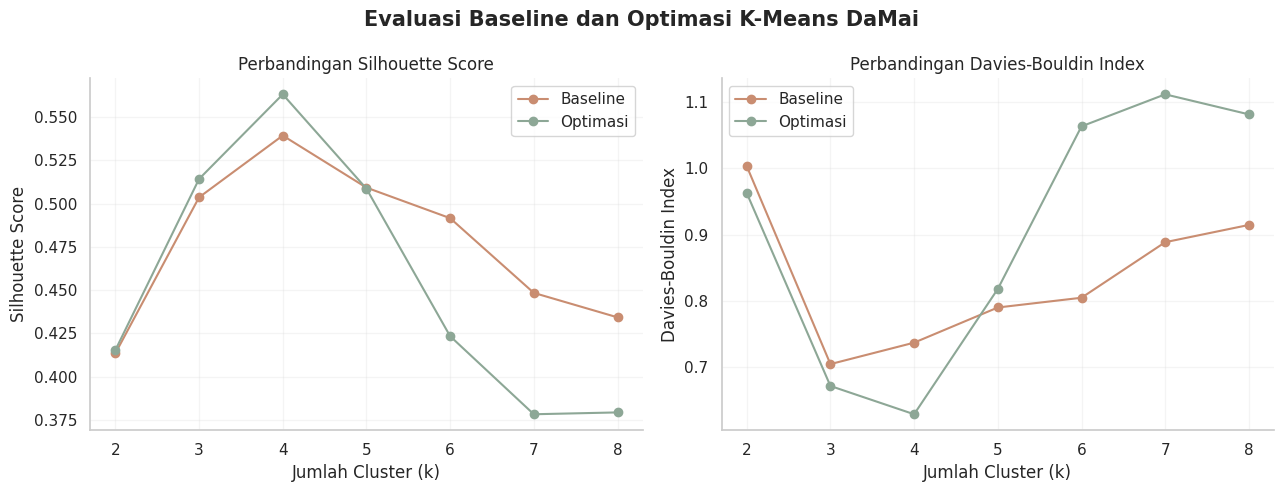

In [32]:

perbandingan = df_baseline[
    ["k", "Silhouette Score", "Davies-Bouldin Index"]
].merge(
    df_optimasi[
        ["k", "Silhouette Score", "Davies-Bouldin Index"]
    ],
    on="k",
    suffixes=("_Baseline", "_Optimasi")
)

display(perbandingan.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    df_baseline["k"],
    df_baseline["Silhouette Score"],
    marker="o",
    color=WARNA["terracotta"],
    label="Baseline"
)

axes[0].plot(
    df_optimasi["k"],
    df_optimasi["Silhouette Score"],
    marker="o",
    color=WARNA["sage"],
    label="Optimasi"
)

axes[0].set_title("Perbandingan Silhouette Score")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].legend()

axes[1].plot(
    df_baseline["k"],
    df_baseline["Davies-Bouldin Index"],
    marker="o",
    color=WARNA["terracotta"],
    label="Baseline"
)

axes[1].plot(
    df_optimasi["k"],
    df_optimasi["Davies-Bouldin Index"],
    marker="o",
    color=WARNA["sage"],
    label="Optimasi"
)

axes[1].set_title("Perbandingan Davies-Bouldin Index")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Davies-Bouldin Index")
axes[1].legend()

for ax in axes:
    ax.set_xticks(range(2, 9))
    ax.grid(alpha=0.2)

plt.suptitle(
    "Evaluasi Baseline dan Optimasi K-Means DaMai",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [33]:

baseline_terbaik = df_baseline.loc[
    df_baseline["Silhouette Score"].idxmax()
]

optimasi_terbaik = df_optimasi.loc[
    df_optimasi["Silhouette Score"].idxmax()
]

if optimasi_terbaik["Silhouette Score"] > baseline_terbaik["Silhouette Score"]:
    metode_terpilih = "Optimasi Log + StandardScaler"
    k_terpilih = int(optimasi_terbaik["k"])
    preprocessing_terpilih = preprocessing_optimasi
    skor_terpilih = optimasi_terbaik["Silhouette Score"]
else:
    metode_terpilih = "Baseline StandardScaler"
    k_terpilih = int(baseline_terbaik["k"])
    preprocessing_terpilih = preprocessing_baseline
    skor_terpilih = baseline_terbaik["Silhouette Score"]

print("HASIL PEMILIHAN MODEL")
print("Metode:", metode_terpilih)
print("Jumlah cluster:", k_terpilih)
print(f"Silhouette Score: {skor_terpilih:.4f}")


HASIL PEMILIHAN MODEL
Metode: Optimasi Log + StandardScaler
Jumlah cluster: 4
Silhouette Score: 0.5632


In [34]:

from sklearn.base import clone

pipeline_final = Pipeline([
    ("preprocessing", clone(preprocessing_terpilih)),
    ("kmeans", KMeans(
        n_clusters=k_terpilih,
        random_state=RANDOM_STATE,
        n_init=10
    ))
])

pipeline_final.fit(X)

label_cluster = pipeline_final.predict(X)

df_segmentasi = df_clean.copy()
df_segmentasi["cluster"] = label_cluster

print("Model berhasil dilatih.")
print("Jumlah cluster:", k_terpilih)
print("Total pelanggan:", len(df_segmentasi))

display(
    df_segmentasi["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Jumlah Pelanggan")
)


Model berhasil dilatih.
Jumlah cluster: 4
Total pelanggan: 10000


,Cluster,Jumlah Pelanggan
0,0,3025
1,1,2990
2,2,1481
3,3,2504


In [35]:

from sklearn.metrics import adjusted_rand_score

hasil_stabilitas = []

for seed in [21, 42, 123]:
    model_uji = Pipeline([
        ("preprocessing", clone(preprocessing_terpilih)),
        ("kmeans", KMeans(
            n_clusters=k_terpilih,
            random_state=seed,
            n_init=10
        ))
    ])

    labels_uji = model_uji.fit_predict(X)

    hasil_stabilitas.append({
        "Random Seed": seed,
        "Adjusted Rand Index": adjusted_rand_score(
            label_cluster, labels_uji
        ),
        "Jumlah Cluster": len(np.unique(labels_uji))
    })

df_stabilitas = pd.DataFrame(hasil_stabilitas)

display(df_stabilitas.round(4))


,Random Seed,Adjusted Rand Index,Jumlah Cluster
0,21,1.0,4
1,42,1.0,4
2,123,1.0,4



## 9. Customer Profiling

Customer Profiling bertujuan mengidentifikasi karakteristik setiap cluster hasil K-Means berdasarkan perilaku transaksi pelanggan.

Analisis dilakukan terhadap jumlah pelanggan, frekuensi transaksi, total belanja, recency, penggunaan promo, nilai rata-rata per transaksi, kategori produk favorit, dan channel pembelian.

Hasil profiling digunakan untuk memberikan nama segmen yang dapat dipahami pemilik UMKM dan menyusun rekomendasi promosi yang relevan.

Penamaan segmen dilakukan setelah profil cluster dianalisis, bukan berdasarkan nomor cluster secara langsung.


In [36]:

df_segmentasi["nilai_per_transaksi_rp"] = (
    df_segmentasi["total_belanja_rp"]
    / df_segmentasi["jumlah_transaksi_6bln"]
    .replace(0, np.nan)
)

df_profil = (
    df_segmentasi.groupby("cluster")
    .agg(
        jumlah_pelanggan=("id_pelanggan", "count"),
        median_transaksi=("jumlah_transaksi_6bln", "median"),
        median_belanja=("total_belanja_rp", "median"),
        median_recency=("hari_sejak_transaksi_terakhir", "median"),
        median_promo=("persen_pakai_promo", "median"),
        median_nilai_transaksi=("nilai_per_transaksi_rp", "median")
    )
    .reset_index()
)

df_profil["persentase_pelanggan"] = (
    df_profil["jumlah_pelanggan"]
    / len(df_segmentasi) * 100
)

display(df_profil.round(2))


,cluster,jumlah_pelanggan,median_transaksi,median_belanja,median_recency,median_promo,median_nilai_transaksi,persentase_pelanggan
0,0,3025,28.0,1313000.0,5.0,20.0,48284.62,30.25
1,1,2990,3.0,98800.0,108.0,34.0,41450.0,29.90
2,2,1481,4.0,1037400.0,30.0,12.0,274600.0,14.81
3,3,2504,11.0,337450.0,12.0,81.0,31779.29,25.04


In [37]:

kategori_proporsi = (
    pd.crosstab(
        df_segmentasi["cluster"],
        df_segmentasi["kategori_favorit"],
        normalize="index"
    ) * 100
)

channel_proporsi = (
    pd.crosstab(
        df_segmentasi["cluster"],
        df_segmentasi["channel_utama"],
        normalize="index"
    ) * 100
)

print("PERSENTASE KATEGORI FAVORIT PER CLUSTER")
display(kategori_proporsi.round(2))

print("PERSENTASE CHANNEL UTAMA PER CLUSTER")
display(channel_proporsi.round(2))


PERSENTASE KATEGORI FAVORIT PER CLUSTER


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
cluster,,,,
0,54.12,4.83,6.28,34.78
1,44.82,10.54,5.35,39.30
2,6.28,42.47,41.59,9.66
3,41.89,5.95,9.35,42.81


PERSENTASE CHANNEL UTAMA PER CLUSTER


channel_utama,gofood,grabfood,shopeefood,toko
cluster,,,,
0,15.67,9.88,5.88,68.56
1,24.68,19.43,15.89,40.00
2,10.20,11.68,19.78,58.34
3,30.95,20.97,29.35,18.73


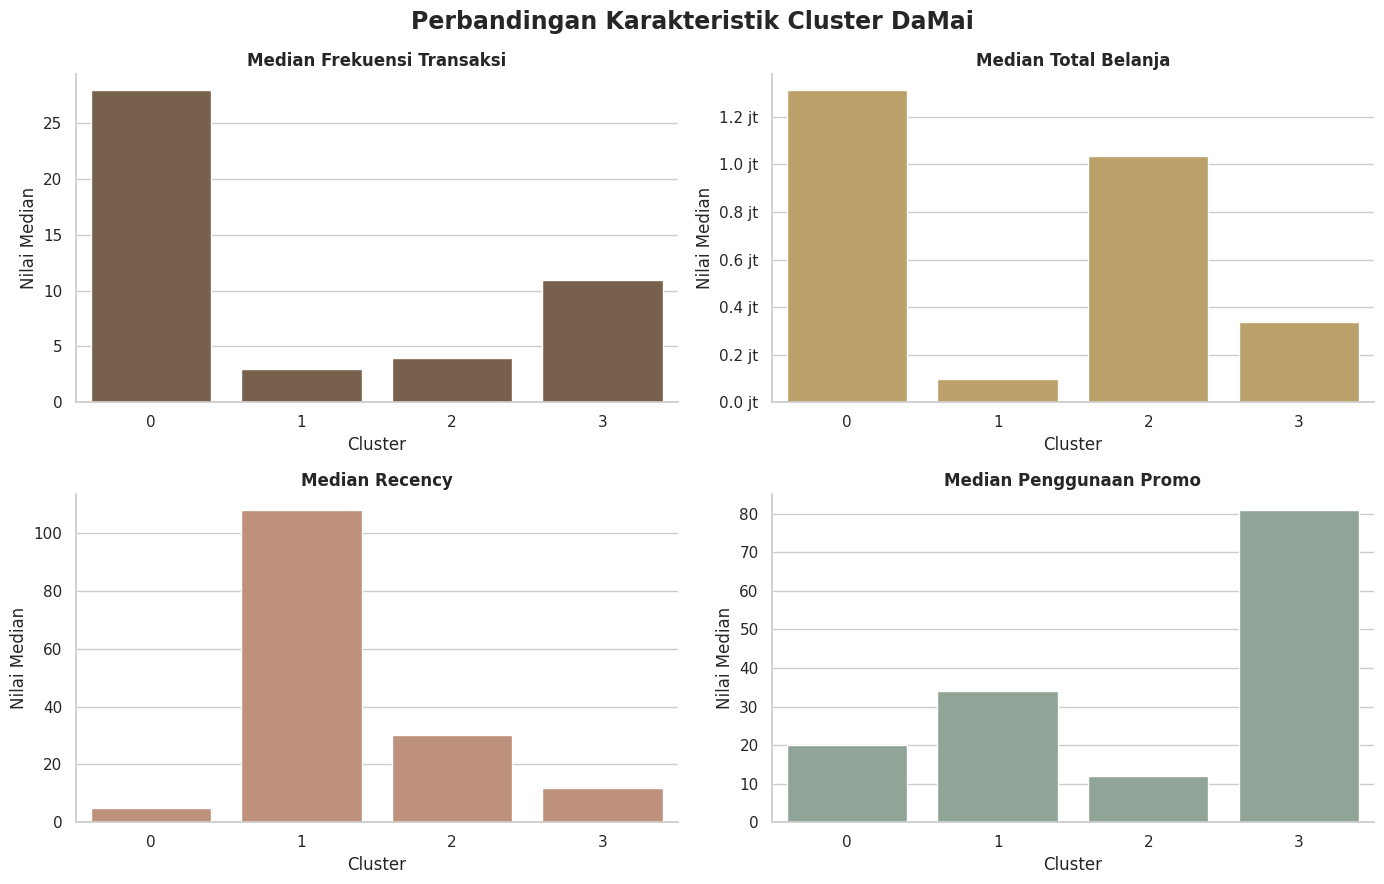

In [38]:

indikator = [
    ("median_transaksi", "Median Frekuensi Transaksi", WARNA["coffee"]),
    ("median_belanja", "Median Total Belanja", WARNA["gold"]),
    ("median_recency", "Median Recency", WARNA["terracotta"]),
    ("median_promo", "Median Penggunaan Promo", WARNA["sage"])
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (kolom, judul, warna) in zip(axes.flat, indikator):
    sns.barplot(
        data=df_profil,
        x="cluster",
        y=kolom,
        color=warna,
        ax=ax
    )

    ax.set_title(judul, fontweight="bold")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Nilai Median")

axes[0, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt")
)

plt.suptitle(
    "Perbandingan Karakteristik Cluster DaMai",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("damai_profil_cluster.png", dpi=200, bbox_inches="tight")
plt.show()


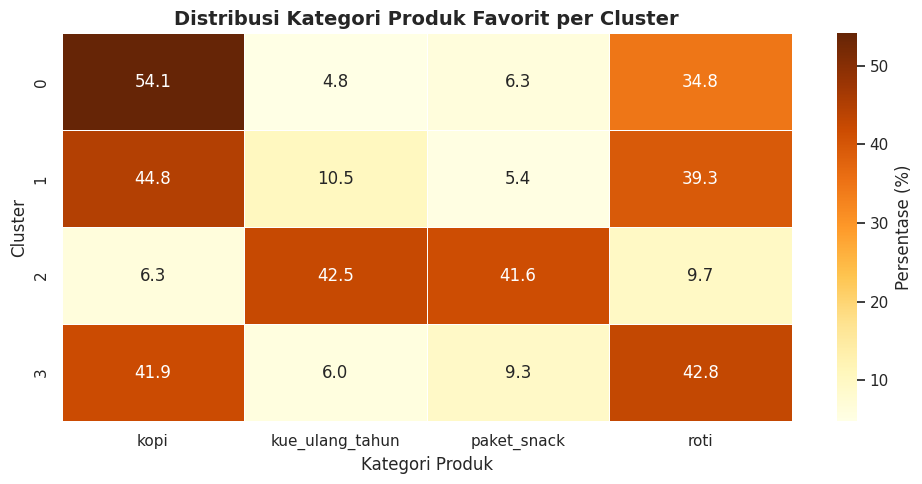

In [39]:

plt.figure(figsize=(10, 5))

sns.heatmap(
    kategori_proporsi,
    annot=True,
    fmt=".1f",
    cmap="YlOrBr",
    linewidths=0.5,
    cbar_kws={"label": "Persentase (%)"}
)

plt.title(
    "Distribusi Kategori Produk Favorit per Cluster",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Kategori Produk")
plt.ylabel("Cluster")

plt.tight_layout()
plt.savefig("damai_kategori_cluster.png", dpi=200, bbox_inches="tight")
plt.show()


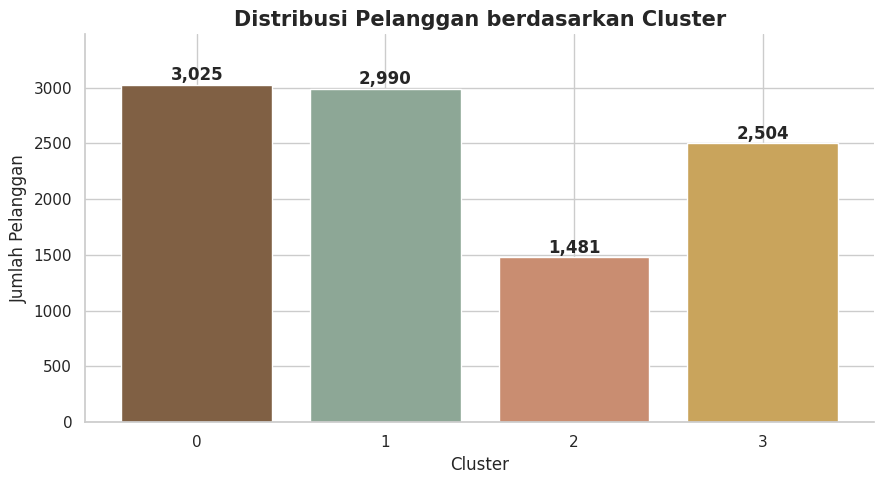

In [40]:

jumlah_cluster = (
    df_segmentasi["cluster"]
    .value_counts()
    .sort_index()
)

warna_cluster = [
    WARNA["coffee"],
    WARNA["sage"],
    WARNA["terracotta"],
    WARNA["gold"]
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    jumlah_cluster.index.astype(str),
    jumlah_cluster.values,
    color=warna_cluster[:len(jumlah_cluster)]
)

for bar in bars:
    tinggi = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi + 40,
        f"{int(tinggi):,}",
        ha="center",
        fontweight="bold"
    )

ax.set_ylim(0, jumlah_cluster.max() * 1.15)
ax.set_title(
    "Distribusi Pelanggan berdasarkan Cluster",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Cluster")
ax.set_ylabel("Jumlah Pelanggan")

plt.tight_layout()
plt.savefig("damai_distribusi_cluster.png", dpi=200, bbox_inches="tight")
plt.show()


In [41]:

df_profil.to_csv(
    "damai_cluster_profiles.csv",
    index=False
)

df_segmentasi.to_csv(
    "damai_customers_clustered.csv",
    index=False
)

assert len(df_segmentasi) == 10000
assert df_segmentasi["id_pelanggan"].is_unique
assert df_segmentasi["cluster"].nunique() == k_terpilih
assert df_profil["jumlah_pelanggan"].sum() == len(df_segmentasi)

print("Customer Profiling berhasil.")
print("Jumlah cluster:", k_terpilih)
print("Jumlah pelanggan:", len(df_segmentasi))
print("File profil dan hasil clustering berhasil disimpan.")


Customer Profiling berhasil.
Jumlah cluster: 4
Jumlah pelanggan: 10000
File profil dan hasil clustering berhasil disimpan.



### 9.1 Interpretasi Segmen Pelanggan

Berdasarkan karakteristik setiap cluster, diperoleh empat segmen pelanggan DaMai Coffee & Bakery:

1. **Loyal Customers (Cluster 0):** Pelanggan dengan frekuensi transaksi tinggi, nilai belanja besar, dan aktivitas pembelian yang konsisten.
2. **Inactive Customers (Cluster 1):** Pelanggan dengan frekuensi transaksi rendah dan waktu yang relatif lama sejak transaksi terakhir.
3. **Occasion Buyers (Cluster 2):** Pelanggan dengan frekuensi pembelian rendah tetapi nilai pembelian per transaksi tinggi. Preferensi terhadap kue ulang tahun dan paket snack menunjukkan pola pembelian untuk kebutuhan tertentu.
4. **Promo Seekers (Cluster 3):** Pelanggan dengan tingkat penggunaan promo yang tinggi dan kecenderungan bertransaksi melalui platform pesan-antar.

Hasil segmentasi ini digunakan sebagai dasar personalisasi promosi. Nama segmen merupakan interpretasi bisnis dari karakteristik cluster, bukan label yang dipelajari langsung oleh algoritma K-Means.


In [42]:

nama_segmen = {
    0: "Loyal Customers",
    1: "Inactive Customers",
    2: "Occasion Buyers",
    3: "Promo Seekers"
}

df_segmentasi["segmen"] = df_segmentasi["cluster"].map(nama_segmen)

assert df_segmentasi["segmen"].notna().all()

ringkasan_segmen = (
    df_segmentasi["segmen"]
    .value_counts()
    .rename_axis("Segmen")
    .reset_index(name="Jumlah Pelanggan")
)

ringkasan_segmen["Persentase (%)"] = (
    ringkasan_segmen["Jumlah Pelanggan"]
    / len(df_segmentasi) * 100
).round(2)

display(ringkasan_segmen)


,Segmen,Jumlah Pelanggan,Persentase (%)
0,Loyal Customers,3025,30.25
1,Inactive Customers,2990,29.90
2,Promo Seekers,2504,25.04
3,Occasion Buyers,1481,14.81


In [43]:

df_profil["segmen"] = df_profil["cluster"].map(nama_segmen)

kolom_profil = [
    "segmen",
    "jumlah_pelanggan",
    "persentase_pelanggan",
    "median_transaksi",
    "median_belanja",
    "median_recency",
    "median_promo",
    "median_nilai_transaksi"
]

display(
    df_profil[kolom_profil]
    .sort_values("jumlah_pelanggan", ascending=False)
    .round(2)
)


,segmen,jumlah_pelanggan,persentase_pelanggan,median_transaksi,median_belanja,median_recency,median_promo,median_nilai_transaksi
0,Loyal Customers,3025,30.25,28.0,1313000.0,5.0,20.0,48284.62
1,Inactive Customers,2990,29.90,3.0,98800.0,108.0,34.0,41450.0
3,Promo Seekers,2504,25.04,11.0,337450.0,12.0,81.0,31779.29
2,Occasion Buyers,1481,14.81,4.0,1037400.0,30.0,12.0,274600.0


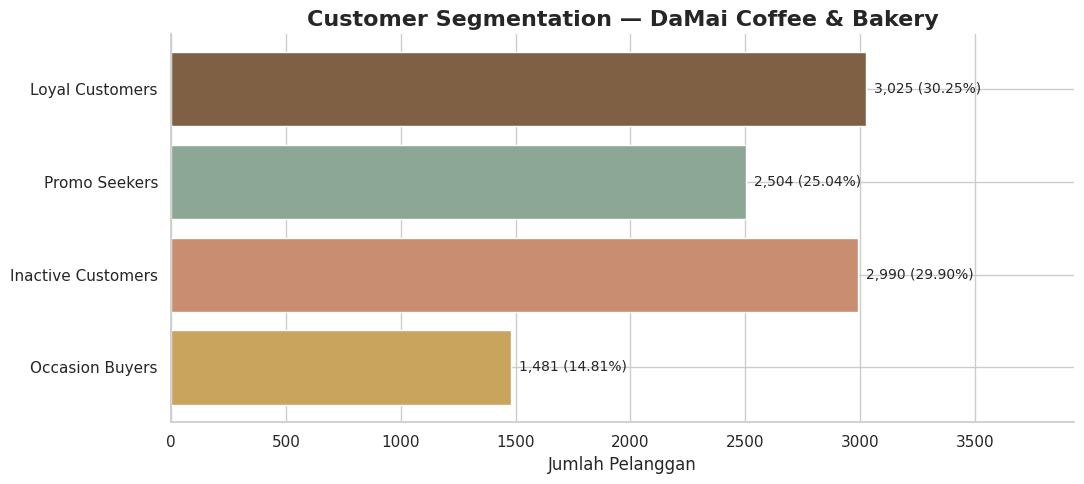

In [44]:

warna_segmen = {
    "Loyal Customers": WARNA["coffee"],
    "Inactive Customers": WARNA["terracotta"],
    "Occasion Buyers": WARNA["gold"],
    "Promo Seekers": WARNA["sage"]
}

urutan_segmen = [
    "Loyal Customers",
    "Promo Seekers",
    "Inactive Customers",
    "Occasion Buyers"
]

jumlah = (
    df_segmentasi["segmen"]
    .value_counts()
    .reindex(urutan_segmen)
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    jumlah.index,
    jumlah.values,
    color=[warna_segmen[s] for s in jumlah.index]
)

ax.invert_yaxis()

for bar in bars:
    nilai = int(bar.get_width())
    ax.text(
        nilai + 35,
        bar.get_y() + bar.get_height() / 2,
        f"{nilai:,} ({nilai / len(df_segmentasi) * 100:.2f}%)",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, jumlah.max() * 1.3)
ax.set_xlabel("Jumlah Pelanggan")
ax.set_ylabel("")
ax.set_title(
    "Customer Segmentation — DaMai Coffee & Bakery",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("damai_customer_segmentation.png", dpi=300, bbox_inches="tight")
plt.show()



## 10. Loyalty Membership DaMai

Selain segmentasi berbasis Machine Learning, DaMai Coffee & Bakery merancang dua tingkatan keanggotaan, yaitu Green Member dan Gold Member.

Program ini bertujuan memberikan penghargaan kepada pelanggan berdasarkan akumulasi nilai belanja.

Ketentuan awal yang disimulasikan:

- **Green Member:** Total belanja selama enam bulan kurang dari Rp1.000.000.
- **Gold Member:** Total belanja selama enam bulan minimal Rp1.000.000.

Membership berbeda dari hasil clustering. Membership ditentukan menggunakan aturan nilai belanja, sedangkan segmen diperoleh dari algoritma K-Means menggunakan beberapa indikator perilaku.

Batas keanggotaan merupakan kebijakan simulasi yang masih perlu dievaluasi berdasarkan kondisi bisnis dan kemampuan UMKM.


In [45]:

BATAS_GOLD = 1_000_000

df_segmentasi["membership"] = np.where(
    df_segmentasi["total_belanja_rp"].fillna(0) >= BATAS_GOLD,
    "Gold",
    "Green"
)

ringkasan_membership = (
    df_segmentasi["membership"]
    .value_counts()
    .rename_axis("Membership")
    .reset_index(name="Jumlah Pelanggan")
)

ringkasan_membership["Persentase (%)"] = (
    ringkasan_membership["Jumlah Pelanggan"]
    / len(df_segmentasi) * 100
).round(2)

display(ringkasan_membership)


,Membership,Jumlah Pelanggan,Persentase (%)
0,Green,7027,70.27
1,Gold,2973,29.73


In [46]:

tabel_membership = pd.crosstab(
    df_segmentasi["segmen"],
    df_segmentasi["membership"]
).reindex(urutan_segmen)

tabel_persentase = (
    pd.crosstab(
        df_segmentasi["segmen"],
        df_segmentasi["membership"],
        normalize="index"
    ) * 100
).reindex(urutan_segmen)

print("JUMLAH PELANGGAN")
display(tabel_membership)

print("PERSENTASE DALAM SETIAP SEGMEN")
display(tabel_persentase.round(2))


JUMLAH PELANGGAN


membership,Gold,Green
segmen,,
Loyal Customers,2197,828
Promo Seekers,0,2504
Inactive Customers,0,2990
Occasion Buyers,776,705


PERSENTASE DALAM SETIAP SEGMEN


membership,Gold,Green
segmen,,
Loyal Customers,72.63,27.37
Promo Seekers,0.00,100.00
Inactive Customers,0.00,100.00
Occasion Buyers,52.40,47.60


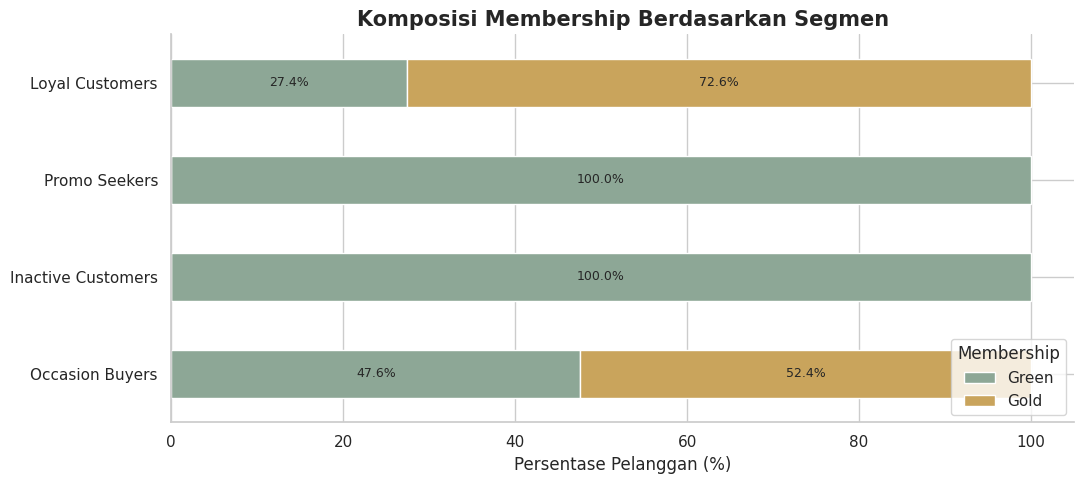

In [47]:

ax = tabel_persentase[["Green", "Gold"]].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 5),
    color=[WARNA["sage"], WARNA["gold"]]
)

ax.invert_yaxis()
ax.set_title(
    "Komposisi Membership Berdasarkan Segmen",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Persentase Pelanggan (%)")
ax.set_ylabel("")
ax.legend(title="Membership", loc="lower right")

for container in ax.containers:
    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() >= 8 else ""
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("damai_membership_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [48]:

df_segmentasi.to_csv(
    "damai_customer_segments.csv",
    index=False
)

df_profil.to_csv(
    "damai_segment_profiles.csv",
    index=False
)

assert df_segmentasi["segmen"].notna().all()
assert df_segmentasi["membership"].isin(["Green", "Gold"]).all()
assert len(df_segmentasi) == 10000

print("Dataset segmentasi dan membership berhasil disimpan.")
print("Jumlah pelanggan:", len(df_segmentasi))
print("Jumlah segmen:", df_segmentasi["segmen"].nunique())
print("Jumlah Gold Member:", (df_segmentasi["membership"] == "Gold").sum())
print("Jumlah Green Member:", (df_segmentasi["membership"] == "Green").sum())


Dataset segmentasi dan membership berhasil disimpan.
Jumlah pelanggan: 10000
Jumlah segmen: 4
Jumlah Gold Member: 2973
Jumlah Green Member: 7027



## 11. Personalized Promotion Recommendation

Hasil segmentasi pelanggan digunakan untuk merancang rekomendasi promosi yang sesuai dengan karakteristik setiap kelompok.

Strategi promosi dibedakan berdasarkan empat segmen:

1. Loyal Customers: mempertahankan loyalitas pelanggan melalui penghargaan transaksi.
2. Inactive Customers: mendorong pelanggan untuk kembali bertransaksi.
3. Occasion Buyers: menawarkan produk paket dan kebutuhan acara.
4. Promo Seekers: memberikan penawaran dengan batas diskon yang terkendali.

Program Green dan Gold Membership digunakan sebagai lapisan benefit tambahan yang terpisah dari hasil clustering.

Seluruh ketentuan promosi merupakan simulasi kebijakan bisnis. Besaran diskon, biaya reward, dan manfaat penjualan belum divalidasi menggunakan margin keuntungan, harga pokok produk, atau eksperimen pemasaran.


In [49]:

strategi_promo = [
    {
        "segmen": "Loyal Customers",
        "nama_promo": "DaMai Loyalty Boost",
        "penawaran": "Bonus 2x poin dasar pada satu transaksi berikutnya",
        "syarat": "Maksimal 100 poin bonus, berlaku 7 hari",
        "tujuan": "Mempertahankan pelanggan aktif",
        "masa_berlaku_hari": 7
    },
    {
        "segmen": "Inactive Customers",
        "nama_promo": "DaMai Welcome Back",
        "penawaran": "Voucher Rp10.000",
        "syarat": "Minimal belanja Rp60.000, satu kali penggunaan, berlaku 7 hari",
        "tujuan": "Mendorong pembelian kembali",
        "masa_berlaku_hari": 7
    },
    {
        "segmen": "Occasion Buyers",
        "nama_promo": "DaMai Celebration Pack",
        "penawaran": "Diskon 5% untuk paket kue dan snack, maksimal Rp25.000",
        "syarat": "Minimal belanja Rp250.000, berlaku 14 hari",
        "tujuan": "Meningkatkan pembelian kebutuhan acara",
        "masa_berlaku_hari": 14
    },
    {
        "segmen": "Promo Seekers",
        "nama_promo": "DaMai Smart Bundle",
        "penawaran": "Diskon 10% untuk paket kopi dan roti, maksimal Rp15.000",
        "syarat": "Minimal belanja Rp75.000, berlaku 7 hari",
        "tujuan": "Mendorong pembelian paket produk",
        "masa_berlaku_hari": 7
    }
]

df_strategi_promo = pd.DataFrame(strategi_promo)

display(df_strategi_promo)


,segmen,nama_promo,penawaran,syarat,tujuan,masa_berlaku_hari
0,Loyal Customers,DaMai Loyalty Boost,Bonus 2x poin dasar pada satu transaksi beriku...,"Maksimal 100 poin bonus, berlaku 7 hari",Mempertahankan pelanggan aktif,7
1,Inactive Customers,DaMai Welcome Back,Voucher Rp10.000,"Minimal belanja Rp60.000, satu kali penggunaan...",Mendorong pembelian kembali,7
2,Occasion Buyers,DaMai Celebration Pack,"Diskon 5% untuk paket kue dan snack, maksimal ...","Minimal belanja Rp250.000, berlaku 14 hari",Meningkatkan pembelian kebutuhan acara,14
3,Promo Seekers,DaMai Smart Bundle,"Diskon 10% untuk paket kopi dan roti, maksimal...","Minimal belanja Rp75.000, berlaku 7 hari",Mendorong pembelian paket produk,7



### 11.1 Benefit Membership

Program membership DaMai dirancang sebagai bentuk penghargaan kepada pelanggan berdasarkan total belanja selama enam bulan.

**Green Member**
- Akses promosi reguler untuk anggota.
- Kesempatan memperoleh penawaran berdasarkan segmen pelanggan.

**Gold Member**
- Seluruh akses Green Member.
- Akses penawaran eksklusif anggota Gold.
- Prioritas informasi paket dan program preorder tertentu.

Benefit membership tidak menggantikan rekomendasi promosi berdasarkan segmen. Keduanya dapat dikombinasikan selama memenuhi persyaratan dan ketentuan bisnis.

Perhitungan poin, mekanisme penukaran reward, dan batas biaya program loyalitas memerlukan kebijakan tambahan sebelum diimplementasikan secara operasional.


In [50]:

peta_promo = df_strategi_promo.set_index("segmen")

benefit_membership = {
    "Green": "Akses promo reguler member",
    "Gold": "Akses promo reguler dan penawaran eksklusif Gold"
}

df_segmentasi["nama_promo"] = df_segmentasi["segmen"].map(
    peta_promo["nama_promo"]
)

df_segmentasi["rekomendasi_promo"] = df_segmentasi["segmen"].map(
    peta_promo["penawaran"]
)

df_segmentasi["syarat_promo"] = df_segmentasi["segmen"].map(
    peta_promo["syarat"]
)

df_segmentasi["tujuan_promo"] = df_segmentasi["segmen"].map(
    peta_promo["tujuan"]
)

df_segmentasi["benefit_membership"] = df_segmentasi["membership"].map(
    benefit_membership
)

df_segmentasi["status_promo"] = "Simulasi - Belum Diaktifkan"

kolom_rekomendasi = [
    "id_pelanggan",
    "segmen",
    "membership",
    "nama_promo",
    "rekomendasi_promo",
    "benefit_membership"
]

display(df_segmentasi[kolom_rekomendasi].head(10))


,id_pelanggan,segmen,membership,nama_promo,rekomendasi_promo,benefit_membership
0,PLG-00001,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member
1,PLG-00002,Occasion Buyers,Green,DaMai Celebration Pack,"Diskon 5% untuk paket kue dan snack, maksimal ...",Akses promo reguler member
2,PLG-00003,Loyal Customers,Green,DaMai Loyalty Boost,Bonus 2x poin dasar pada satu transaksi beriku...,Akses promo reguler member
3,PLG-00004,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member
4,PLG-00005,Promo Seekers,Green,DaMai Smart Bundle,"Diskon 10% untuk paket kopi dan roti, maksimal...",Akses promo reguler member
5,PLG-00006,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member
6,PLG-00007,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member
7,PLG-00008,Occasion Buyers,Gold,DaMai Celebration Pack,"Diskon 5% untuk paket kue dan snack, maksimal ...",Akses promo reguler dan penawaran eksklusif Gold
8,PLG-00009,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member
9,PLG-00010,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,Akses promo reguler member


In [51]:

def rekomendasi_pelanggan(segmen, membership):
    if segmen not in peta_promo.index:
        raise ValueError("Segmen pelanggan tidak dikenali.")

    if membership not in benefit_membership:
        raise ValueError("Membership pelanggan tidak dikenali.")

    promo = peta_promo.loc[segmen]

    return {
        "segmen": segmen,
        "membership": membership,
        "nama_promo": promo["nama_promo"],
        "rekomendasi": promo["penawaran"],
        "syarat": promo["syarat"],
        "tujuan": promo["tujuan"],
        "benefit_membership": benefit_membership[membership],
        "status": "Simulasi"
    }

contoh_rekomendasi = rekomendasi_pelanggan(
    "Loyal Customers",
    "Gold"
)

display(pd.DataFrame([contoh_rekomendasi]).T)


,0
segmen,Loyal Customers
membership,Gold
nama_promo,DaMai Loyalty Boost
rekomendasi,Bonus 2x poin dasar pada satu transaksi beriku...
syarat,"Maksimal 100 poin bonus, berlaku 7 hari"
tujuan,Mempertahankan pelanggan aktif
benefit_membership,Akses promo reguler dan penawaran eksklusif Gold
status,Simulasi


In [52]:

contoh_semua_segmen = []

for segmen in urutan_segmen:
    pelanggan = df_segmentasi[
        df_segmentasi["segmen"] == segmen
    ].iloc[0]

    contoh_semua_segmen.append(
        rekomendasi_pelanggan(
            pelanggan["segmen"],
            pelanggan["membership"]
        )
    )

display(pd.DataFrame(contoh_semua_segmen))


,segmen,membership,nama_promo,rekomendasi,syarat,tujuan,benefit_membership,status
0,Loyal Customers,Green,DaMai Loyalty Boost,Bonus 2x poin dasar pada satu transaksi beriku...,"Maksimal 100 poin bonus, berlaku 7 hari",Mempertahankan pelanggan aktif,Akses promo reguler member,Simulasi
1,Promo Seekers,Green,DaMai Smart Bundle,"Diskon 10% untuk paket kopi dan roti, maksimal...","Minimal belanja Rp75.000, berlaku 7 hari",Mendorong pembelian paket produk,Akses promo reguler member,Simulasi
2,Inactive Customers,Green,DaMai Welcome Back,Voucher Rp10.000,"Minimal belanja Rp60.000, satu kali penggunaan...",Mendorong pembelian kembali,Akses promo reguler member,Simulasi
3,Occasion Buyers,Green,DaMai Celebration Pack,"Diskon 5% untuk paket kue dan snack, maksimal ...","Minimal belanja Rp250.000, berlaku 14 hari",Meningkatkan pembelian kebutuhan acara,Akses promo reguler member,Simulasi


In [53]:

assert df_segmentasi["nama_promo"].notna().all()
assert df_segmentasi["rekomendasi_promo"].notna().all()
assert df_segmentasi["benefit_membership"].notna().all()

assert len(df_segmentasi) == 10000
assert df_segmentasi["id_pelanggan"].is_unique

assert (
    df_segmentasi["membership"].value_counts().get("Gold", 0)
    == 2973
)

assert (
    df_segmentasi["membership"].value_counts().get("Green", 0)
    == 7027
)

assert (
    df_segmentasi.groupby("segmen")["nama_promo"].nunique()
    == 1
).all()

print("Seluruh pengujian rekomendasi berhasil.")
print("Total pelanggan:", len(df_segmentasi))
print("Total segmen:", df_segmentasi["segmen"].nunique())
print("Total strategi promo:", len(df_strategi_promo))
print("Rekomendasi kosong:", df_segmentasi["nama_promo"].isna().sum())


Seluruh pengujian rekomendasi berhasil.
Total pelanggan: 10000
Total segmen: 4
Total strategi promo: 4
Rekomendasi kosong: 0


In [54]:

df_segmentasi.to_csv(
    "damai_customer_recommendations.csv",
    index=False
)

df_strategi_promo.to_csv(
    "damai_promotion_strategy.csv",
    index=False
)

print("File rekomendasi berhasil disimpan.")
print("1. damai_customer_recommendations.csv")
print("2. damai_promotion_strategy.csv")


File rekomendasi berhasil disimpan.
1. damai_customer_recommendations.csv
2. damai_promotion_strategy.csv



## 12. Prediksi Segmen Pelanggan

Tahap ini mengimplementasikan model K-Means terpilih untuk mengelompokkan pelanggan berdasarkan ringkasan transaksi selama enam bulan.

Sistem menerima empat informasi, yaitu jumlah transaksi, total belanja, hari sejak transaksi terakhir, dan persentase penggunaan promo.

Data input diproses menggunakan pipeline preprocessing yang sama dengan tahap pelatihan. Selanjutnya, K-Means menentukan cluster berdasarkan kedekatan terhadap centroid yang telah dipelajari.

Hasil cluster diterjemahkan menjadi nama segmen pelanggan. Tingkat membership Green atau Gold ditentukan melalui aturan nilai belanja, sedangkan rekomendasi promo ditentukan berdasarkan strategi bisnis setiap segmen.

Fitur ini ditujukan untuk pelanggan yang memiliki riwayat transaksi, tetapi belum tercatat dalam dataset pelatihan. Pelanggan yang sama sekali belum memiliki riwayat pembelian memerlukan mekanisme penanganan tersendiri.


In [55]:

def prediksi_pelanggan(
    jumlah_transaksi_6bln,
    total_belanja_rp,
    hari_sejak_transaksi_terakhir,
    persen_pakai_promo
):
    nilai = [
        jumlah_transaksi_6bln,
        total_belanja_rp,
        hari_sejak_transaksi_terakhir,
        persen_pakai_promo
    ]

    if not all(np.isfinite(float(v)) for v in nilai):
        raise ValueError("Seluruh input harus berupa angka yang valid.")

    if jumlah_transaksi_6bln < 1 or not float(jumlah_transaksi_6bln).is_integer():
        raise ValueError("Jumlah transaksi harus bilangan bulat positif.")

    if total_belanja_rp <= 0:
        raise ValueError("Total belanja harus lebih dari nol.")

    if hari_sejak_transaksi_terakhir < 0:
        raise ValueError("Recency tidak boleh negatif.")

    if not 0 <= persen_pakai_promo <= 100:
        raise ValueError("Persentase promo harus berada pada rentang 0–100.")

    data_input = pd.DataFrame([{
        "hari_sejak_transaksi_terakhir": hari_sejak_transaksi_terakhir,
        "jumlah_transaksi_6bln": jumlah_transaksi_6bln,
        "total_belanja_rp": total_belanja_rp,
        "persen_pakai_promo": persen_pakai_promo
    }])

    cluster = int(
        pipeline_final.predict(data_input[fitur_clustering])[0]
    )

    segmen = nama_segmen[cluster]

    membership = (
        "Gold" if total_belanja_rp >= BATAS_GOLD else "Green"
    )

    rekomendasi = rekomendasi_pelanggan(segmen, membership)

    return {
        "cluster": cluster,
        "segmen": segmen,
        "membership": membership,
        "nama_promo": rekomendasi["nama_promo"],
        "rekomendasi": rekomendasi["rekomendasi"],
        "syarat": rekomendasi["syarat"],
        "tujuan": rekomendasi["tujuan"],
        "benefit_membership": rekomendasi["benefit_membership"],
        "status": "Simulasi"
    }

print("Fungsi prediksi pelanggan berhasil dibuat.")


Fungsi prediksi pelanggan berhasil dibuat.


In [56]:

hasil_prediksi = prediksi_pelanggan(
    jumlah_transaksi_6bln=28,
    total_belanja_rp=1300000,
    hari_sejak_transaksi_terakhir=5,
    persen_pakai_promo=20
)

print("HASIL ANALISIS PELANGGAN DAMAI")
print("-" * 40)
print("Segmen:", hasil_prediksi["segmen"])
print("Membership:", hasil_prediksi["membership"])
print("Promo:", hasil_prediksi["nama_promo"])
print("Penawaran:", hasil_prediksi["rekomendasi"])
print("Syarat:", hasil_prediksi["syarat"])
print("Benefit:", hasil_prediksi["benefit_membership"])


HASIL ANALISIS PELANGGAN DAMAI
----------------------------------------
Segmen: Loyal Customers
Membership: Gold
Promo: DaMai Loyalty Boost
Penawaran: Bonus 2x poin dasar pada satu transaksi berikutnya
Syarat: Maksimal 100 poin bonus, berlaku 7 hari
Benefit: Akses promo reguler dan penawaran eksklusif Gold


In [57]:

pelanggan_uji = pd.DataFrame([
    {
        "kode": "DM-001",
        "jumlah_transaksi_6bln": 28,
        "total_belanja_rp": 1300000,
        "hari_sejak_transaksi_terakhir": 5,
        "persen_pakai_promo": 20
    },
    {
        "kode": "DM-002",
        "jumlah_transaksi_6bln": 3,
        "total_belanja_rp": 100000,
        "hari_sejak_transaksi_terakhir": 108,
        "persen_pakai_promo": 34
    },
    {
        "kode": "DM-003",
        "jumlah_transaksi_6bln": 4,
        "total_belanja_rp": 1040000,
        "hari_sejak_transaksi_terakhir": 30,
        "persen_pakai_promo": 12
    },
    {
        "kode": "DM-004",
        "jumlah_transaksi_6bln": 11,
        "total_belanja_rp": 340000,
        "hari_sejak_transaksi_terakhir": 12,
        "persen_pakai_promo": 80
    }
])

hasil_simulasi = []

for _, pelanggan in pelanggan_uji.iterrows():
    hasil = prediksi_pelanggan(
        jumlah_transaksi_6bln=pelanggan["jumlah_transaksi_6bln"],
        total_belanja_rp=pelanggan["total_belanja_rp"],
        hari_sejak_transaksi_terakhir=pelanggan["hari_sejak_transaksi_terakhir"],
        persen_pakai_promo=pelanggan["persen_pakai_promo"]
    )

    hasil_simulasi.append({
        "Kode": pelanggan["kode"],
        "Segmen": hasil["segmen"],
        "Membership": hasil["membership"],
        "Promo": hasil["nama_promo"]
    })

df_hasil_simulasi = pd.DataFrame(hasil_simulasi)

display(df_hasil_simulasi)


,Kode,Segmen,Membership,Promo
0,DM-001,Loyal Customers,Gold,DaMai Loyalty Boost
1,DM-002,Inactive Customers,Green,DaMai Welcome Back
2,DM-003,Occasion Buyers,Gold,DaMai Celebration Pack
3,DM-004,Promo Seekers,Green,DaMai Smart Bundle


In [58]:

skenario_invalid = [
    (-2, 150000, 10, 20),
    (4, -100000, 10, 20),
    (4, 150000, -5, 20),
    (4, 150000, 10, 150),
    (0, 150000, 10, 20)
]

jumlah_tertangani = 0

for skenario in skenario_invalid:
    try:
        prediksi_pelanggan(*skenario)
    except ValueError:
        jumlah_tertangani += 1

assert jumlah_tertangani == len(skenario_invalid)

print("Seluruh pengujian validasi input berhasil.")
print("Skenario diuji:", len(skenario_invalid))
print("Input tidak valid ditolak:", jumlah_tertangani)


Seluruh pengujian validasi input berhasil.
Skenario diuji: 5
Input tidak valid ditolak: 5



## 13. Persiapan Implementasi Model

Model clustering yang telah dipilih disimpan bersama pipeline preprocessing agar dapat digunakan kembali tanpa melakukan pelatihan ulang.

Paket model mencakup:

- Pipeline preprocessing dan K-Means yang sudah dilatih.
- Daftar fitur input beserta urutannya.
- Pemetaan nomor cluster ke nama segmen.
- Aturan Green dan Gold Membership.
- Strategi rekomendasi promo.
- Informasi konfigurasi dan hasil evaluasi model.

Paket disimpan menggunakan format Joblib dan selanjutnya digunakan sebagai komponen Machine Learning pada aplikasi DaMai Coffee & Bakery berbasis Streamlit.

Model merupakan prototipe akademik berbasis data simulasi dan belum diuji pada transaksi operasional UMKM yang sebenarnya.


In [59]:

import joblib
import sklearn

paket_model = {
    "nama_proyek": "DaMai Coffee & Bakery",
    "pipeline": pipeline_final,
    "fitur": fitur_clustering,
    "nama_segmen": nama_segmen,
    "batas_gold": BATAS_GOLD,
    "strategi_promo": df_strategi_promo.set_index(
        "segmen"
    ).to_dict(orient="index"),
    "benefit_membership": benefit_membership,
    "metode": metode_terpilih,
    "jumlah_cluster": k_terpilih,
    "silhouette_score": float(skor_terpilih),
    "random_state": RANDOM_STATE,
    "versi_sklearn": sklearn.__version__
}

joblib.dump(
    paket_model,
    "damai_model_bundle.joblib",
    compress=3
)

print("Model berhasil disimpan.")
print("Nama file: damai_model_bundle.joblib")
print("Metode:", metode_terpilih)
print("Jumlah cluster:", k_terpilih)
print("Versi scikit-learn:", sklearn.__version__)


Model berhasil disimpan.
Nama file: damai_model_bundle.joblib
Metode: Optimasi Log + StandardScaler
Jumlah cluster: 4
Versi scikit-learn: 1.6.1


In [60]:

model_dimuat = joblib.load(
    "damai_model_bundle.joblib"
)

contoh_input = pd.DataFrame([{
    "hari_sejak_transaksi_terakhir": 5,
    "jumlah_transaksi_6bln": 28,
    "total_belanja_rp": 1300000,
    "persen_pakai_promo": 20
}])

prediksi_awal = pipeline_final.predict(
    contoh_input[fitur_clustering]
)

prediksi_ulang = model_dimuat["pipeline"].predict(
    contoh_input[model_dimuat["fitur"]]
)

assert np.array_equal(prediksi_awal, prediksi_ulang)

cluster_uji = int(prediksi_ulang[0])
segmen_uji = model_dimuat["nama_segmen"][cluster_uji]

print("Pengujian model tersimpan berhasil.")
print("Cluster:", cluster_uji)
print("Segmen:", segmen_uji)
print("Hasil sebelum dan sesudah penyimpanan identik.")


Pengujian model tersimpan berhasil.
Cluster: 0
Segmen: Loyal Customers
Hasil sebelum dan sesudah penyimpanan identik.


In [61]:

from zipfile import ZipFile
from pathlib import Path

daftar_file = [
    "damai_model_bundle.joblib",
    "damai_customer_recommendations.csv",
    "damai_promotion_strategy.csv",
    "damai_segment_profiles.csv",
    "damai_customer_segmentation.png",
    "damai_membership_distribution.png"
]

with ZipFile("DaMai_ML_Artifacts.zip", "w") as arsip:
    for nama_file in daftar_file:
        if Path(nama_file).exists():
            arsip.write(nama_file)

print("Paket berhasil dibuat: DaMai_ML_Artifacts.zip")

with ZipFile("DaMai_ML_Artifacts.zip") as arsip:
    print("\nIsi paket:")
    for nama_file in arsip.namelist():
        print("-", nama_file)


Paket berhasil dibuat: DaMai_ML_Artifacts.zip

Isi paket:
- damai_model_bundle.joblib
- damai_customer_recommendations.csv
- damai_promotion_strategy.csv
- damai_segment_profiles.csv
- damai_customer_segmentation.png
- damai_membership_distribution.png


In [62]:

from google.colab import files

files.download("DaMai_ML_Artifacts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:

from google.colab import files
from zipfile import ZipFile

df_baseline.to_csv("damai_baseline_metrics.csv", index=False)
df_optimasi.to_csv("damai_optimized_metrics.csv", index=False)

with ZipFile("DaMai_Evaluation.zip", "w") as zip_file:
    zip_file.write("damai_baseline_metrics.csv")
    zip_file.write("damai_optimized_metrics.csv")

files.download("DaMai_Evaluation.zip")

print("Hasil evaluasi berhasil diekspor.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Hasil evaluasi berhasil diekspor.



## 14. Kesimpulan

Proyek Machine Learning DaMai Coffee & Bakery berhasil mengembangkan sistem segmentasi pelanggan UMKM menggunakan algoritma K-Means Clustering berdasarkan empat indikator perilaku, yaitu Recency, Frequency, Monetary, dan penggunaan promo.

Dari 10.150 baris data awal, diperoleh 10.000 pelanggan unik setelah proses pembersihan. Eksperimen K-Means dilakukan untuk k=2 hingga k=8 dengan membandingkan preprocessing baseline dan optimasi.

Model terbaik menggunakan transformasi logaritmik pada fitur RFM dan StandardScaler, dengan empat cluster. Model memperoleh Silhouette Score sebesar 0,5632 dan Davies-Bouldin Index sebesar 0,6295, lebih baik dibandingkan baseline yang menghasilkan 0,5394 dan 0,7373.

Keempat cluster diinterpretasikan menjadi:

1. Loyal Customers: 3.025 pelanggan (30,25%).
2. Inactive Customers: 2.990 pelanggan (29,90%).
3. Occasion Buyers: 1.481 pelanggan (14,81%).
4. Promo Seekers: 2.504 pelanggan (25,04%).

Pengujian kestabilan pada tiga random seed menghasilkan Adjusted Rand Index sebesar 1,0 terhadap model acuan.

Model berhasil diintegrasikan ke aplikasi web DaMai berbasis Streamlit untuk menampilkan dashboard, data pelanggan, profil segmentasi, prediksi pelanggan, membership Green/Gold, rekomendasi promosi, dan evaluasi model.

Dengan demikian, proyek menunjukkan bahwa clustering dapat dimanfaatkan untuk mengidentifikasi pola pelanggan dan mendukung penyusunan strategi pemasaran yang lebih terarah.



## 15. Keterbatasan dan Pengembangan

### 15.1 Keterbatasan

1. Dataset merupakan data simulasi untuk pembelajaran, sehingga hasil segmentasi belum mewakili kondisi pelanggan UMKM yang sebenarnya.
2. Model hanya menggunakan empat indikator perilaku transaksi dan belum mempertimbangkan seluruh faktor yang mungkin memengaruhi keputusan pembelian.
3. Nilai yang hilang ditangani melalui imputasi median, sehingga sebagian informasi pelanggan merupakan hasil pendekatan statistik.
4. Evaluasi clustering mengukur kualitas pengelompokan, bukan keberhasilan promosi atau peningkatan penjualan.
5. Aturan membership dan rekomendasi promo masih berupa simulasi yang belum divalidasi berdasarkan margin keuntungan, biaya promosi, atau pengujian langsung.
6. Aplikasi belum terhubung dengan sistem transaksi operasional sehingga input pelanggan baru masih dilakukan secara manual.

### 15.2 Saran Pengembangan

Pengembangan selanjutnya dapat dilakukan melalui integrasi data transaksi aktual, pembaruan model secara berkala, evaluasi perubahan perilaku pelanggan, dan pengujian efektivitas promosi.

Validasi bisnis dapat dilakukan melalui eksperimen pemasaran, misalnya membandingkan tingkat penukaran promo dan pembelian ulang antara pelanggan yang menerima promosi berdasarkan segmen dan kelompok pembanding.

Hasil model juga perlu dievaluasi kembali ketika terdapat perubahan karakteristik pelanggan atau pola transaksi.

## 16. Penutup

DaMai Coffee & Bakery merupakan prototipe akademik yang menggabungkan analisis data, unsupervised learning, dan aplikasi web untuk mendukung pengambilan keputusan pemasaran UMKM.

Seluruh hasil analisis, model, dan rekomendasi dalam proyek ini digunakan untuk tujuan pembelajaran.
